# StreamView Analytics: limpieza, EDA y preparación del dashboard

Esta es la versión corregida de nuestro notebook. Integramos las fuentes originales de películas y series, dejamos una fila por título y generamos **dos CSV**: `data/content_clean.csv` y `data/content_financials.csv`.

**Audiencias:** Directorio y Gerencia de Contenidos y Adquisición. Se aborda la visión consolidada del catálogo y, especialmente, los problemas 2 (popularidad por género) y 6 (características de contenidos mejor evaluados y populares).

**Orden:** comprensión y carga → diagnóstico → limpieza → EDA visual → conclusiones y valores de control → validaciones → exportación final. Todos los gráficos y resultados están guardados en este notebook.

**Ejecución local:** abrir este notebook y seleccionar «Ejecutar todo». Las rutas detectan la raíz del repositorio tanto desde `notebooks/` como desde la raíz. También se puede ejecutar `python src/ejecutar_eda.py` desde la raíz. Los CSV se escriben en `data/` y las 13 figuras en `images/eda/`.

**Google Colab:** con el repositorio completo disponible, ejecutar desde su raíz o desde `notebooks/`. Si se usa únicamente el notebook, subir los dos CSV originales cuando se soliciten. Se generarán `data/` e `images/eda/` dentro del directorio de trabajo de Colab. No se modifican los originales. Dependencias e instrucciones en `README.md`.

**Cambios frente a la versión anterior:** la nota pasa de `vote_average_x100` a `vote_average_x1000`; los ratios financieros de `roi_x1000` a `roi_x1000000`; se recuperan importes positivos bajos con una bandera; se distinguen equilibrio e ingresos superiores/inferiores al presupuesto. Se mantienen los demás campos usados por el dashboard y la definición de alto potencial por medianas de cada tipo.


## 1. Comprensión del negocio y parámetros

Cada registro representa un contenido del extracto, no a un usuario ni a una reproducción individual. El parámetro popularity refleja el interés relativo de la obra cinematográfica, vote_average la calificación (de 0 a 10) y vote_count el total de votos recibidos.

El umbral de 50 votos responde a un criterio práctico interno, no a una garantía de representatividad estadística. Además, se utiliza USD por convención para este análisis, ya que los datos originales no especifican la moneda ni contemplan costos de licencias, marketing o distribución.


In [ ]:
import os, re, glob, zipfile, csv
from pathlib import Path
import numpy as np
import pandas as pd
pd.set_option('display.width', 220, 'display.max_columns', 60, 'display.max_colwidth', 80)

MIN_VOTES = 50        # Votos mínimos para considerar confiable una calificación
FIN_REVIEW_LIMIT = 10_000  # Umbral de revisión: se conservan los importes positivos bajos.
DATE_FORMAT = '%d/%m/%Y'
def project_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / 'notebooks' / '01_limpieza_datos.ipynb').is_file() and (candidate / 'data' / 'raw').is_dir():
            return candidate
    return current  # Notebook independiente en Colab: carga interactiva de archivos originales

PROJECT_ROOT = project_root()
OUT_DIR = str(PROJECT_ROOT / 'data')
FIGURES_DIR = PROJECT_ROOT / 'images' / 'eda'
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ISO 3166-1 alfa-2 por pais (para el mapa de Looker Studio). 'ZZ' = sin pais unico.
COUNTRY_ISO = {'Afghanistan': 'AF',
 'Albania': 'AL',
 'Algeria': 'DZ',
 'Angola': 'AO',
 'Argentina': 'AR',
 'Armenia': 'AM',
 'Aruba': 'AW',
 'Australia': 'AU',
 'Austria': 'AT',
 'Azerbaijan': 'AZ',
 'Bahamas': 'BS',
 'Bangladesh': 'BD',
 'Belarus': 'BY',
 'Belgium': 'BE',
 'Bhutan': 'BT',
 'Bolivia': 'BO',
 'Bosnia and Herzegovina': 'BA',
 'Botswana': 'BW',
 'Brazil': 'BR',
 'Brunei Darussalam': 'BN',
 'Bulgaria': 'BG',
 'Cambodia': 'KH',
 'Cameroon': 'CM',
 'Canada': 'CA',
 'Cayman Islands': 'KY',
 'Central African Republic': 'CF',
 'Chile': 'CL',
 'China': 'CN',
 'Colombia': 'CO',
 'Congo': 'CG',
 "Cote D'Ivoire": 'CI',
 'Croatia': 'HR',
 'Cuba': 'CU',
 'Cyprus': 'CY',
 'Czech Republic': 'CZ',
 'Denmark': 'DK',
 'Dominican Republic': 'DO',
 'Ecuador': 'EC',
 'Egypt': 'EG',
 'Estonia': 'EE',
 'Ethiopia': 'ET',
 'Faeroe Islands': 'FO',
 'Fiji': 'FJ',
 'Finland': 'FI',
 'France': 'FR',
 'French Polynesia': 'PF',
 'Georgia': 'GE',
 'Germany': 'DE',
 'Ghana': 'GH',
 'Greece': 'GR',
 'Greenland': 'GL',
 'Guadaloupe': 'GP',
 'Guatemala': 'GT',
 'Hong Kong': 'HK',
 'Hungary': 'HU',
 'Iceland': 'IS',
 'India': 'IN',
 'Indonesia': 'ID',
 'Iran': 'IR',
 'Iraq': 'IQ',
 'Ireland': 'IE',
 'Israel': 'IL',
 'Italy': 'IT',
 'Japan': 'JP',
 'Jordan': 'JO',
 'Kazakhstan': 'KZ',
 'Kenya': 'KE',
 'Kosovo': 'XK',
 'Kuwait': 'KW',
 'Kyrgyz Republic': 'KG',
 "Lao People's Democratic Republic": 'LA',
 'Latvia': 'LV',
 'Lebanon': 'LB',
 'Liechtenstein': 'LI',
 'Lithuania': 'LT',
 'Luxembourg': 'LU',
 'Macao': 'MO',
 'Macedonia': 'MK',
 'Malawi': 'MW',
 'Malaysia': 'MY',
 'Malta': 'MT',
 'Mauritania': 'MR',
 'Mauritius': 'MU',
 'Mexico': 'MX',
 'Monaco': 'MC',
 'Mongolia': 'MN',
 'Montenegro': 'ME',
 'Morocco': 'MA',
 'Myanmar': 'MM',
 'Namibia': 'NA',
 'Nepal': 'NP',
 'Netherlands': 'NL',
 'Netherlands Antilles': 'AN',
 'New Caledonia': 'NC',
 'New Zealand': 'NZ',
 'Nicaragua': 'NI',
 'Nigeria': 'NG',
 'Norway': 'NO',
 'Pakistan': 'PK',
 'Palau': 'PW',
 'Palestinian Territory': 'PS',
 'Panama': 'PA',
 'Paraguay': 'PY',
 'Peru': 'PE',
 'Philippines': 'PH',
 'Poland': 'PL',
 'Portugal': 'PT',
 'Puerto Rico': 'PR',
 'Qatar': 'QA',
 'Romania': 'RO',
 'Russia': 'RU',
 'Rwanda': 'RW',
 'Saudi Arabia': 'SA',
 'Senegal': 'SN',
 'Serbia': 'RS',
 'Singapore': 'SG',
 'Slovakia': 'SK',
 'Slovenia': 'SI',
 'Solomon Islands': 'SB',
 'South Africa': 'ZA',
 'South Korea': 'KR',
 'Spain': 'ES',
 'Sri Lanka': 'LK',
 'St. Kitts and Nevis': 'KN',
 'St. Lucia': 'LC',
 'St. Pierre and Miquelon': 'PM',
 'Sweden': 'SE',
 'Switzerland': 'CH',
 'Syrian Arab Republic': 'SY',
 'Taiwan': 'TW',
 'Tanzania': 'TZ',
 'Thailand': 'TH',
 'Tunisia': 'TN',
 'Turkey': 'TR',
 'US Virgin Islands': 'VI',
 'Uganda': 'UG',
 'Ukraine': 'UA',
 'United Arab Emirates': 'AE',
 'United Kingdom': 'GB',
 'United States': 'US',
 'United States Minor Outlying Islands': 'UM',
 'Uruguay': 'UY',
 'Uzbekistan': 'UZ',
 'Vanuatu': 'VU',
 'Venezuela': 'VE',
 'Vietnam': 'VN',
 'Zambia': 'ZM'}

# Codigo de idioma (ISO 639-1 / TMDB) a nombre
LANGUAGE_NAME = {'af': 'Afrikaans',
 'am': 'Amharic',
 'ar': 'Arabic',
 'as': 'Assamese',
 'az': 'Azerbaijani',
 'bg': 'Bulgarian',
 'bn': 'Bengali',
 'bs': 'Bosnian',
 'ca': 'Catalan',
 'cn': 'Cantonese',
 'cs': 'Czech',
 'cy': 'Welsh',
 'da': 'Danish',
 'de': 'German',
 'dz': 'Dzongkha',
 'el': 'Greek',
 'en': 'English',
 'es': 'Spanish',
 'et': 'Estonian',
 'eu': 'Basque',
 'fa': 'Persian',
 'fi': 'Finnish',
 'fr': 'French',
 'ga': 'Irish',
 'gl': 'Galician',
 'he': 'Hebrew',
 'hi': 'Hindi',
 'hr': 'Croatian',
 'ht': 'Haitian Creole',
 'hu': 'Hungarian',
 'hy': 'Armenian',
 'id': 'Indonesian',
 'is': 'Icelandic',
 'it': 'Italian',
 'ja': 'Japanese',
 'ka': 'Georgian',
 'kk': 'Kazakh',
 'kl': 'Greenlandic',
 'km': 'Khmer',
 'kn': 'Kannada',
 'ko': 'Korean',
 'ku': 'Kurdish',
 'ky': 'Kyrgyz',
 'la': 'Latin',
 'lb': 'Luxembourgish',
 'lt': 'Lithuanian',
 'lv': 'Latvian',
 'mi': 'Māori',
 'mk': 'Macedonian',
 'ml': 'Malayalam',
 'mn': 'Mongolian',
 'mr': 'Marathi',
 'ms': 'Malay',
 'mt': 'Maltese',
 'nb': 'Norwegian Bokmål',
 'ne': 'Nepali',
 'nl': 'Dutch',
 'no': 'Norwegian',
 'or': 'Odia',
 'pa': 'Punjabi',
 'pl': 'Polish',
 'ps': 'Pashto',
 'pt': 'Portuguese',
 'ro': 'Romanian',
 'ru': 'Russian',
 'si': 'Sinhala',
 'sk': 'Slovak',
 'sl': 'Slovenian',
 'sr': 'Serbian',
 'sv': 'Swedish',
 'ta': 'Tamil',
 'te': 'Telugu',
 'th': 'Thai',
 'tl': 'Tagalog',
 'tr': 'Turkish',
 'uk': 'Ukrainian',
 'ur': 'Urdu',
 'vi': 'Vietnamese',
 'xx': 'No language',
 'yo': 'Yoruba',
 'za': 'Zhuang',
 'zh': 'Chinese',
 'zu': 'Zulu'}
import hashlib
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_rows', 35)
sns.set_theme(style='whitegrid')
COLORS = {'Película':'#2563EB','Serie':'#F59E0B'}
plt.rcParams.update({'figure.figsize':(11,5),'figure.dpi':120,'axes.titlesize':14})
MIN_GROUP = 30

# Exportar exactamente las mismas figuras mostradas en el único notebook.
_show_original = getattr(plt.show, '_streamview_original', plt.show)
_figure_number = 0
def show_and_save(*args, **kwargs):
    global _figure_number
    figures = [plt.figure(number) for number in plt.get_fignums()]
    for figure in figures:
        _figure_number += 1
        figure.savefig(FIGURES_DIR / f'eda_{_figure_number:02d}.png', dpi=160, bbox_inches='tight')
    _show_original(*args, **kwargs)
    for figure in figures:
        plt.close(figure)
show_and_save._streamview_original = _show_original
plt.show = show_and_save


## 2. Carga y trazabilidad de las fuentes

Las huellas SHA-256 identifican exactamente los archivos utilizados. Se comprueba el esquema y se muestran registros de ambas fuentes antes de transformarlas.


In [2]:
NAMES = {'movies': 'netflix_movies_detailed_up_to_2025.csv', 'tv': 'netflix_tv_shows_detailed_up_to_2025.csv'}

def locate(name):
    for base in (PROJECT_ROOT / 'data' / 'raw', Path.cwd()):
        p = os.path.join(base, name)
        if os.path.exists(p):
            return p
    return None

def have_all():
    return all(locate(n) for n in NAMES.values())

if not have_all():
    for z in glob.glob('*.zip'):
        zipfile.ZipFile(z).extractall('.')
if not have_all():
    try:
        from google.colab import files
        files.upload()                       # subir Data_Movies.zip (o los 2 CSV)
        for z in glob.glob('*.zip'):
            zipfile.ZipFile(z).extractall('.')
    except ImportError:
        pass
assert have_all(), 'No se encontraron los dos CSV originales (ver celda de carga).'

movies_raw = pd.read_csv(locate(NAMES['movies']))
tv_raw = pd.read_csv(locate(NAMES['tv']))
print('peliculas:', movies_raw.shape, '| series:', tv_raw.shape)
display(pd.DataFrame([{'archivo':locate(name),'filas':len(d),'columnas':len(d.columns),
    'sha256':hashlib.sha256(Path(locate(name)).read_bytes()).hexdigest()}
    for name,d in [(NAMES['movies'],movies_raw),(NAMES['tv'],tv_raw)]]))
display(movies_raw.head(3)); display(tv_raw.head(3))
display(pd.concat([pd.DataFrame({'fuente':n,'campo':d.columns,'tipo':d.dtypes.astype(str).values})
    for n,d in [('Películas',movies_raw),('Series',tv_raw)]],ignore_index=True))


peliculas: (16000, 18) | series: (16000, 16)


,archivo,filas,columnas,sha256
0,data/raw/netflix_movies_detailed_up_to_2025.csv,16000,18,5439bcc05ccc4c170265a88e115891adecef64a330060dbd55266ac7fea14613
1,data/raw/netflix_tv_shows_detailed_up_to_2025.csv,16000,16,16156fb21d0139a396b3a72cd58d66f86d272f7607df9281c2abfe68f59f80d7


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average,budget,revenue
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antonio Banderas, Walt Dohrn",United States of America,2010-05-16,2010,6.380,NaN,"Comedy, Adventure, Fantasy, Animation, Family",en,"A bored and domesticated Shrek pacts with deal-maker Rumpelstiltskin to get back to feeling like a real ogre again, but when he's duped and sent to a twisted version of Far Far Away—where Rumpelstiltskin is king, ogres are hunted, and he and Fiona have never met—he sets out to restore his world and reclaim his true love.",203.893,7449,6.380,165000000,752600867
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken Watanabe, Tom Hardy, Elliot Page","United Kingdom, United States of America",2010-07-15,2010,8.369,NaN,"Action, Science Fiction, Adventure",en,"Cobb, a skilled thief who commits corporate espionage by infiltrating the subconscious of his targets is offered a chance to regain his old life as payment for a task considered to be impossible: ""inception"", the implantation of another person's idea into a target's subconscious.",156.242,37119,8.369,160000000,839030630
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, Toby Jones, Helena Bonham Carter","United Kingdom, United States of America",2010-11-17,2010,7.744,NaN,"Adventure, Fantasy",en,"Harry, Ron and Hermione walk away from their last year at Hogwarts to find and destroy the remaining Horcruxes, putting an end to Voldemort's bid for immortality. But with Harry's beloved Dumbledore dead and Voldemort's unscrupulous Death Eaters on the loose, the world is more dangerous than ever.",121.191,19327,7.744,250000000,954305868


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average
0,33238,TV Show,Running Man,안재철,"Yoo Jae-suk, Jee Seok-jin, Kim Jong-kook, Haha, Song Ji-hyo",South Korea,2010-07-11,2010,8.241,1 Seasons,"Comedy, Reality",ko,A reality and competition show where members are joined by celebs to complete a weekly mission to win the race with Seoul as the beautiful backdrop.,1929.898,187,8.241
1,32415,TV Show,Conan,NaN,"Conan O'Brien, Andy Richter",United States of America,2010-11-08,2010,7.035,1 Seasons,"Talk, Comedy, News",en,A late night television talk show hosted by Conan O'Brien.,1670.580,229,7.035
2,37757,TV Show,MasterChef Greece,NaN,NaN,Greece,2010-10-03,2010,5.600,1 Seasons,Reality,el,MasterChef Greece is a Greek competitive cooking game show. It's an adaptation of the British show MasterChef.,1317.092,6,5.600


,fuente,campo,tipo
0,Películas,show_id,int64
1,Películas,type,object
2,Películas,title,object
3,Películas,director,object
4,Películas,cast,object
5,Películas,country,object
6,Películas,date_added,object
7,Películas,release_year,int64
8,Películas,rating,float64
9,Películas,duration,float64


## 3. Diagnóstico original: nulos, dominios y duplicados

Diferenciamos entre datos faltantes, ceros no registrados, filas duplicadas y valores atípicos. Conservamos todas las cifras positivas, ya que un monto bajo o un índice elevado no implican necesariamente un error en la fuente.

============ Peliculas (16000, 18)
Columnas con nulos: {'director': 132, 'cast': 204, 'country': 466, 'duration': 16000, 'genres': 107, 'description': 132}
Filas duplicadas: 0 | show_id repetidos: 0
rating identica a vote_average: True
vote_count = 0: 894 | con 0 votos pero calificacion > 0: 0 | con menos de MIN_VOTES votos: 3815
date_added: 2010-01-01 a 2025-12-25 | mismo anio que release_year: 100.0 %
titulos por anio de estreno (valores distintos): [np.int64(1000)]
campos de texto con comillas dobles: 770 | con saltos de linea: 18
============ Series (16000, 16)
Columnas con nulos: {'director': 10965, 'cast': 1157, 'country': 1797, 'genres': 974, 'description': 3206}
Filas duplicadas: 0 | show_id repetidos: 9
rating identica a vote_average: True
vote_count = 0: 3674 | con 0 votos pero calificacion > 0: 13 | con menos de MIN_VOTES votos: 12788
date_added: 2010-01-01 a 2025-12-31 | mismo anio que release_year: 100.0 %
titulos por anio de estreno (valores distintos): [np.int64(1000)]
c

,fuente,campo,nulos,% nulos,distintos
0,Películas,show_id,0,0.00,16000
1,Películas,type,0,0.00,1
2,Películas,title,0,0.00,15485
3,Películas,director,132,0.82,9508
4,Películas,cast,204,1.27,15639
5,Películas,country,466,2.91,1463
6,Películas,date_added,0,0.00,4423
7,Películas,release_year,0,0.00,16
8,Películas,rating,0,0.00,2145
9,Películas,duration,16000,100.00,0


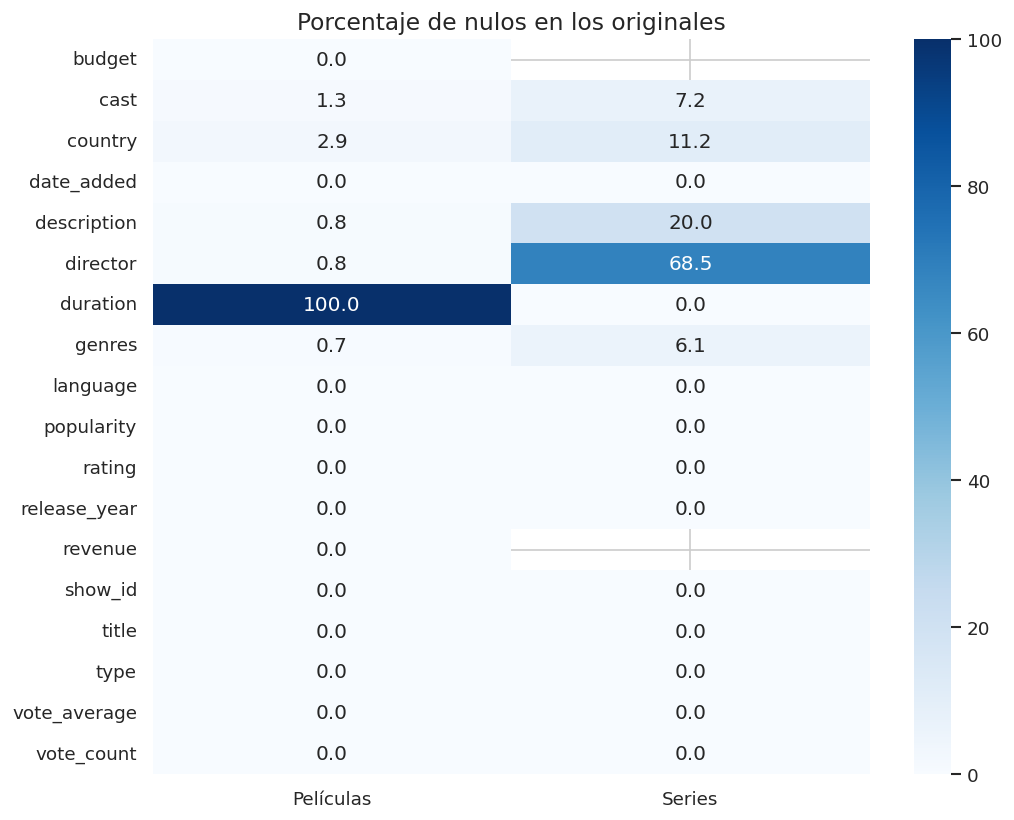

,count,mean,std,min,25%,50%,75%,max
show_id,16000.0,5.266582e+05,3.794427e+05,189.00,225725.75000,446817.0000,7.739808e+05,1.440471e+06
release_year,16000.0,2.017500e+03,4.609916e+00,2010.00,2013.75000,2017.5000,2.021250e+03,2.025000e+03
rating,16000.0,5.956368e+00,1.754741e+00,0.00,5.60000,6.3000,6.923000e+00,1.000000e+01
duration,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,16000.0,2.038473e+01,6.861003e+01,3.86,7.84075,10.9135,1.733650e+01,3.876006e+03
vote_count,16000.0,7.186561e+02,2.080198e+03,0.00,53.00000,138.0000,4.220000e+02,3.711900e+04
vote_average,16000.0,5.956368e+00,1.754741e+00,0.00,5.60000,6.3000,6.923000e+00,1.000000e+01
budget,16000.0,8.766792e+06,2.912450e+07,0.00,0.00000,0.0000,2.200000e+06,4.600000e+08
revenue,16000.0,2.446308e+07,1.116977e+08,0.00,0.00000,0.0000,1.654473e+06,2.799439e+09


,count,mean,std,min,25%,50%,75%,max
show_id,16000.0,126567.673375,75640.760545,767.000,67867.75000,94380.5000,206920.7500,285345.000
release_year,16000.0,2017.500000,4.609916,2010.000,2013.75000,2017.5000,2021.2500,2025.000
rating,16000.0,5.417107,3.266492,0.000,2.70000,6.8000,7.8000,10.000
popularity,16000.0,64.850984,139.387289,2.323,24.87475,36.1875,62.1875,6421.923
vote_count,16000.0,107.014313,607.461581,0.000,1.00000,4.0000,30.0000,24664.000
vote_average,16000.0,5.417107,3.266492,0.000,2.70000,6.8000,7.8000,10.000


,show_id,title,release_year,vote_count,vote_average,popularity
15540,252630,Joe Lycett’s United States of Birmingham,2025,0,0.0,11.531
15539,252630,Joe Lycett’s United States of Birmingham,2025,0,0.0,11.550
15358,278867,Ensemble,2025,1,7.0,11.044
15360,278867,Ensemble,2025,1,7.0,18.407
15398,279457,Ghassan & Mina,2025,0,0.0,9.631
15400,279457,Ghassan & Mina,2025,0,0.0,16.051
15479,279739,Settle Down,2025,0,0.0,15.215
15480,279739,Settle Down,2025,0,0.0,13.135
15519,280651,Master in 3 Months: Edo Period,2025,0,0.0,16.794
15520,280651,Master in 3 Months: Edo Period,2025,0,0.0,11.996


In [3]:
def diagnostico(df, nombre):
    print('=' * 12, nombre, df.shape)
    nulos = df.isna().sum()
    print('Columnas con nulos:', {k: int(v) for k, v in nulos[nulos > 0].items()})
    print('Filas duplicadas:', int(df.duplicated().sum()), '| show_id repetidos:', int(df['show_id'].duplicated().sum()))
    print('rating identica a vote_average:', bool((df['rating'] == df['vote_average']).all()))
    print('vote_count = 0:', int((df['vote_count'] == 0).sum()),
          '| con 0 votos pero calificacion > 0:', int(((df['vote_count'] == 0) & (df['vote_average'] > 0)).sum()),
          '| con menos de MIN_VOTES votos:', int((df['vote_count'] < MIN_VOTES).sum()))
    d = pd.to_datetime(df['date_added'])
    print('date_added:', d.min().date(), 'a', d.max().date(), '| mismo anio que release_year:', round(float((d.dt.year == df['release_year']).mean()) * 100, 1), '%')
    print('titulos por anio de estreno (valores distintos):', sorted(df.groupby('release_year').size().unique()))
    txt = df[['title', 'director', 'cast', 'country', 'genres', 'description']]
    print('campos de texto con comillas dobles:', int(txt.apply(lambda s: s.str.contains('"', na=False)).sum().sum()),
          '| con saltos de linea:', int(txt.apply(lambda s: s.str.contains(r'[\r\n]', na=False)).sum().sum()))

diagnostico(movies_raw, 'Peliculas'); diagnostico(tv_raw, 'Series')
print()
print('duration: peliculas nulas =', int(movies_raw['duration'].isna().sum()), '| series valores unicos =', tv_raw['duration'].dropna().unique())
print('show_id compartidos entre peliculas y series:', len(set(movies_raw['show_id']) & set(tv_raw['show_id'])))
print('popularidad mediana: peliculas', round(movies_raw['popularity'].median(), 2), '| series', round(tv_raw['popularity'].median(), 2))
print('budget = 0:', int((movies_raw['budget'] == 0).sum()), '| revenue = 0:', int((movies_raw['revenue'] == 0).sum()),
      '| budget en (0, FIN_REVIEW_LIMIT):', int(((movies_raw['budget'] > 0) & (movies_raw['budget'] < FIN_REVIEW_LIMIT)).sum()),
      '| revenue en (0, FIN_REVIEW_LIMIT):', int(((movies_raw['revenue'] > 0) & (movies_raw['revenue'] < FIN_REVIEW_LIMIT)).sum()))
quality_raw=pd.concat([pd.DataFrame({'fuente':name,'campo':d.columns,
    'nulos':d.isna().sum().values,'% nulos':(d.isna().mean()*100).round(2).values,
    'distintos':d.nunique(dropna=True).values})
    for name,d in [('Películas',movies_raw),('Series',tv_raw)]],ignore_index=True)
display(quality_raw)
fig,ax=plt.subplots(figsize=(9,7))
sns.heatmap(quality_raw.pivot(index='campo',columns='fuente',values='% nulos'),
    annot=True,fmt='.1f',vmin=0,vmax=100,cmap='Blues',ax=ax)
ax.set_title('Porcentaje de nulos en los originales');ax.set_xlabel('');ax.set_ylabel('')
plt.tight_layout();plt.show()
display(movies_raw.describe().T); display(tv_raw.describe().T)
for name,d in [('Película',movies_raw),('Serie',tv_raw)]:
    assert d.show_id.notna().all() and d.title.notna().all()
    assert d.vote_average.between(0,10).all()
    assert d.vote_count.ge(0).all() and d.popularity.ge(0).all()
    assert np.isclose(d.vote_average*1000,(d.vote_average*1000).round(),atol=1e-7,rtol=0).all()
    assert np.isclose(d.popularity*1000,(d.popularity*1000).round(),atol=1e-7,rtol=0).all()
    print(name,': dominios válidos; precisión de notas y popularidad de hasta tres decimales.')
display(tv_raw[tv_raw.show_id.duplicated(keep=False)][
    ['show_id','title','release_year','vote_count','vote_average','popularity']].sort_values('show_id'))


,Película,Serie
release_year,,
2010,1000,1000
2011,1000,1000
2012,1000,1000
2013,1000,1000
2014,1000,1000
2015,1000,1000
2016,1000,1000
2017,1000,1000
2018,1000,1000


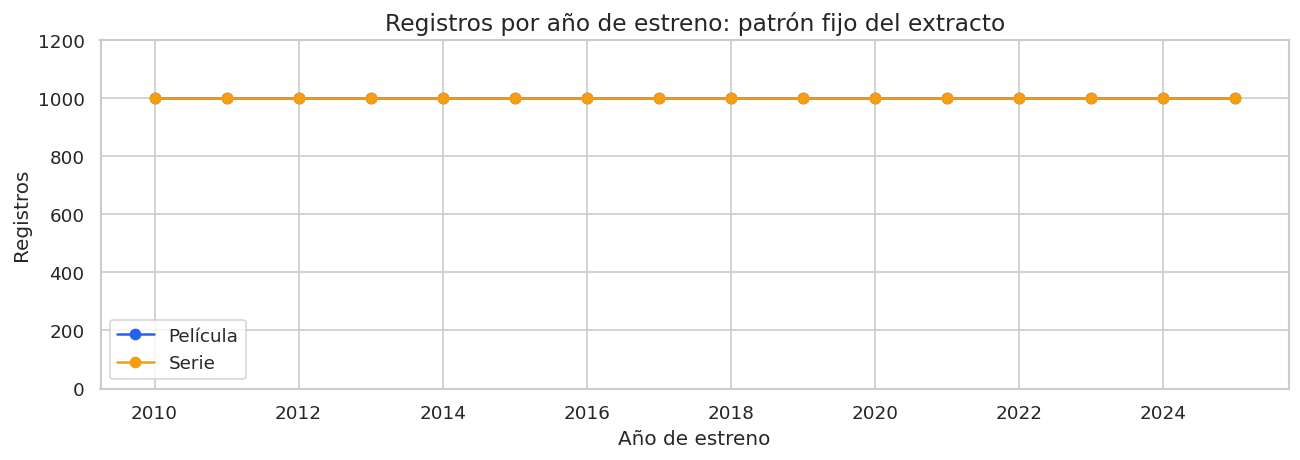

In [4]:
raw_years=pd.DataFrame({'Película':movies_raw.groupby('release_year').size(),
                        'Serie':tv_raw.groupby('release_year').size()})
display(raw_years)
fig,ax=plt.subplots(figsize=(11,4))
raw_years.plot(marker='o',ax=ax,color=[COLORS['Película'],COLORS['Serie']])
ax.set_title('Registros por año de estreno: patrón fijo del extracto')
ax.set_xlabel('Año de estreno');ax.set_ylabel('Registros');ax.set_ylim(0,1200)
plt.tight_layout();plt.show()


### Diagnóstico confirmado y reglas de limpieza

| Hallazgo | Decisión |
|---|---|
| 1.000 registros por año y tipo en los originales | Describir el extracto; no inferir crecimiento del catálogo real. El patrón sugiere selección por cupos, pero no se dispone del método de extracción. |
| Nueve repeticiones de ID en series | Conservar más votos y, en empate, mayor popularidad. No existe fecha de actualización; ese desempate puede sesgar al alza nueve títulos. |
| IDs numéricos compartidos entre películas y series | Crear `content_id` con prefijo M/T. |
| `rating` duplica exactamente la nota | Excluirlo: no contiene clasificación etaria. |
| Duración vacía en películas y constante en series | Excluirla del análisis; no inventar duraciones ni temporadas. |
| Reparto y descripción disponibles | Conservarlos para exploración y contexto, sin utilizarlos como cifras agregables. |
| Cero votos | Convertir la nota en nula. |
| Notas originales de tres decimales | Exportar `vote_average_x1000` y clasificar con esa misma precisión. |
| Finanzas en cero | Considerar información no disponible por convención del caso; excluir de ratios si falta presupuesto o ingresos positivos. |
| Importes positivos menores a USD 10.000 | Conservar y marcar para revisión, no declararlos falsos. |
| Fecha cuyo año siempre coincide con el estreno | Conservar `date_added` por compatibilidad. Su significado de incorporación no está verificado; el análisis temporal usa `release_year`. |
| Países multivalor sin país principal verificado | Mantener «Coproducción internacional»; los mapas de país único excluyen esas producciones. |
| Géneros combinados en series |Esta homologación responde a un agrupamiento con fines puramente analíticos y no valida subgéneros de forma individual. |

Normalizamos los textos para la exportación (espacios y saltos de línea) y reemplazamos las comillas dobles por simples, manteniendo el criterio del archivo anterior. Los datos originales conservan su escritura inicial para garantizar la trazabilidad, mientras que los nombres en inglés de países, idiomas y géneros se preservan para no alterar los filtros existentes.


## 4. Limpieza e integración de películas y series

La tabla principal mantiene una fila por título. Las listas de países, géneros y personas solo se expanden temporalmente para el EDA, sin multiplicar los registros del CSV principal.


In [5]:
log = []
def note(paso, detalle, n):
    log.append({'paso': paso, 'detalle': detalle, 'filas_afectadas': int(n)})

def clean_text(series):
    s = series.astype('string')
    n_quotes = int(s.str.contains('"', na=False).sum())
    s = (s.str.replace(r'[\r\n\t]+', ' ', regex=True).str.replace('"', "'", regex=False)
          .str.replace(r'\s+', ' ', regex=True).str.strip())
    return s.replace('', pd.NA), n_quotes

def prepare(raw, kind):
    d = raw.copy()
    assert (d['rating'] == d['vote_average']).all()
    d = d.drop(columns=['rating', 'duration', 'type'])
    d['content_type'] = kind
    d['content_id'] = ('M' if kind == 'Película' else 'T') + d['show_id'].astype(str)
    return d

movies = prepare(movies_raw, 'Película'); tv = prepare(tv_raw, 'Serie')
note('Columnas', 'Se eliminan rating (duplica vote_average), duration (vacía/constante); se conservan description y cast', len(movies) + len(tv))

# Duplicados por id dentro de cada tipo: se conserva la fila con mas votos (y luego mas popularidad)
for nombre, d in (('películas', movies), ('series', tv)):
    antes = len(d)
    d.sort_values(['vote_count', 'popularity'], ascending=False, inplace=True)
    d.drop_duplicates('content_id', keep='first', inplace=True)
    d.sort_index(inplace=True)
    note('Duplicados', f'{nombre}: show_id repetido, se conserva una fila por id', antes - len(d))

df = pd.concat([movies, tv], ignore_index=True).rename(columns={'show_id': 'tmdb_id'})
note('Integración', 'Se unen películas y series en una sola tabla; content_id evita choques de show_id entre tipos', len(df))
assert df['content_id'].is_unique

# Texto
for c in ['title', 'director', 'cast', 'description', 'country', 'genres']:
    df[c], nq = clean_text(df[c])
    if nq: note('Texto', f'{c}: comillas dobles reemplazadas por simples (Looker Studio)', nq)
assert df['title'].notna().all()
for c, etiqueta in (('director', 'Sin información'), ('country', 'Sin información'), ('genres', 'Sin información'), ('cast','Sin información'), ('description','Sin información')):
    n = int(df[c].isna().sum()); df[c] = df[c].fillna(etiqueta)
    note('Valores faltantes', f'{c} nulo pasa a "{etiqueta}"', n)
df['genres_source']=df['genres']


In [6]:
# Géneros: homologar categorias combinadas de series y definir genero principal
GENRE_FIX = {'Action & Adventure': ['Action', 'Adventure'], 'Sci-Fi & Fantasy': ['Science Fiction', 'Fantasy'],
             'War & Politics': ['War', 'Politics'], 'Unknown': []}
def genre_list(s):
    out = []
    for g in (x.strip() for x in s.split(',')):
        if g == 'Sin información': continue
        out.extend(GENRE_FIX.get(g, [g]))
    out = list(dict.fromkeys(out))
    return out or ['Sin información']
gl = df['genres'].apply(genre_list)
df['genres'] = gl.apply(', '.join)
df['genre_main'] = gl.str[0]
df['n_genres'] = gl.apply(lambda l: 0 if l == ['Sin información'] else len(l))
note('Estandarización', 'genres: categorías combinadas de series separadas; genre_main = primer género de la lista', int((df['content_type'] == 'Serie').sum()))

# Paises: nombre unico y codigo ISO; sin pais principal en el origen
df['country'] = df['country'].str.replace('United States of America', 'United States', regex=False)
cl = df['country'].apply(lambda s: [] if s == 'Sin información' else [x.strip() for x in s.split(',')])
df['n_countries'] = cl.apply(len)
unmapped = sorted({c for l in cl for c in l} - set(COUNTRY_ISO))
assert not unmapped, unmapped
df['tipo_produccion'] = np.select([df['n_countries'] == 0, df['n_countries'] == 1], ['Sin información', 'Un solo país'], default='Coproducción')
df['country_main'] = np.select([df['n_countries'] == 0, df['n_countries'] == 1],
                               ['Sin información', cl.str[0].where(df['n_countries'] == 1, 'x')], default='Coproducción internacional')
df['country_iso2'] = df['country_main'].map(COUNTRY_ISO).fillna('ZZ')
note('Estandarización', 'country_main = país si es uno solo; "Coproducción internacional" si hay varios (el orden de la lista es casi alfabético, no indica país principal)', int((df['n_countries'] > 1).sum()))

# Idioma
df['language_code'] = df['language']
df['language'] = df['language_code'].map(LANGUAGE_NAME)
assert df['language'].notna().all(), df.loc[df['language'].isna(), 'language_code'].unique()
note('Estandarización', 'language: código a nombre en inglés (misma lengua que géneros y países)', len(df))


### Países y géneros: alcance de las categorías

country_main solo registra un país cuando la producción indica uno solo; etiquetas como «Coproducción internacional» o «Sin información» no se consideran países. Además, country_iso2 = ZZ es un código interno no geográfico que debemos excluir del mapa.

Por su parte, genre_main toma simplemente el primer género de la lista, sin verificar si es el principal. Mantendremos el agrupamiento original en genres_source; al comparar países participantes o géneros asociados, trabajaremos con las listas completas y un conteo único de títulos. Ten en cuenta que un mismo título puede figurar en varios grupos, por lo que no debemos sumar estos conteos para obtener el total general.


In [ ]:
# Fechas conservadas por compatibilidad con el dashboard.
df['date_added']=pd.to_datetime(df.date_added,format='%Y-%m-%d',errors='raise')
assert df.date_added.dt.year.eq(df.release_year).all()
df['month_added']=df.date_added.dt.month
df['release_period']=pd.cut(df.release_year,[2009,2014,2019,2025],
    labels=['2010-2014','2015-2019','2020-2025']).astype(str)
df['release_period_years']=df.release_period.map({'2010-2014':5,'2015-2019':5,'2020-2025':6}).astype(int)

# Escalas enteras: una sola precisión canónica para etiquetas y cálculos.
sin_votos=df.vote_count.eq(0)
df.loc[sin_votos,'vote_average']=np.nan
df['vote_average_x1000']=(df.vote_average*1000).round().astype('Int64')
df['vote_average']=df.vote_average_x1000.astype(float)/1000
df['popularity_x1000']=(df.popularity*1000).round().astype('int64')
df['popularity']=df.popularity_x1000/1000
df['es_confiable']=(df.vote_count.ge(MIN_VOTES)&df.vote_average.notna()).astype(int)
df['rating_confiable']=np.where(df.es_confiable.eq(1),'Sí','No')
df['es_7_o_mas']=(df.es_confiable.eq(1)&df.vote_average_x1000.ge(7000).fillna(False)).astype(int)
band=pd.cut(df.vote_average_x1000.astype(float),[0,5000,6000,7000,8000,10001],right=False,
    labels=['0 a <5','5 a <6','6 a <7','7 a <8','8 a 10'])
df['rating_band']=band.astype(object).where(band.notna(),'Sin calificación')
df['popularity_pct_tipo']=(df.groupby('content_type').popularity.rank(pct=True)*100).round().clip(lower=1).astype(int)

# Se conserva la definición relativa de alto potencial.
conf=df.es_confiable.eq(1)
thresholds_scaled=df[conf].groupby('content_type').agg(
    nota_mediana_x1000=('vote_average_x1000','median'),
    popularidad_mediana_x1000=('popularity_x1000','median'))
umbrales=(thresholds_scaled.astype(float)/1000).rename(columns={
    'nota_mediana_x1000':'mediana_calificacion','popularidad_mediana_x1000':'mediana_popularidad'})
display(umbrales)
u=df.join(thresholds_scaled,on='content_type')
alta_cal=u.vote_average_x1000.ge(u.nota_mediana_x1000).fillna(False)
alta_pop=u.popularity_x1000.ge(u.popularidad_mediana_x1000)
df['cuadrante']=np.select([~conf,alta_cal&alta_pop,alta_cal&~alta_pop,~alta_cal&alta_pop],
    ['Sin calificación confiable','Alta calificación y alta popularidad',
     'Alta calificación y baja popularidad','Baja calificación y alta popularidad'],
    default='Baja calificación y baja popularidad')
df['es_alto_potencial']=df.cuadrante.eq('Alta calificación y alta popularidad').astype(int)

df['title_label']=df.title+' ('+df.release_year.astype(str)+')'
rep=df.title_label.duplicated(keep=False)
df.loc[rep,'title_label']=df.loc[rep,'title_label']+' ['+df.loc[rep,'content_id']+']'
assert df.title_label.is_unique
note('Notas','Nota x1000; rangos, >=7 y cuadrantes usan la misma precisión',len(df))
note('Fechas','Se conserva el período 2020-2025 y se explicita su duración de seis años',len(df))


,mediana_calificacion,mediana_popularidad
content_type,,
Película,6.400,11.4400
Serie,7.599,47.6225


### Definición de alto potencial

Entre títulos con al menos 50 votos, se calculan las medianas de nota y popularidad **por tipo**. «Alto potencial» identifica contenidos en o por encima de ambas medianas. Es una etiqueta exploratoria relativa, no un pronóstico de éxito ni una evaluación de rentabilidad.

Las etiquetas quedan calculadas sobre el extracto completo. Aplicar filtros del dashboard reduce los títulos visibles, pero no recalcula automáticamente esos umbrales. Los percentiles de popularidad son rangos redondeados de 1–100 dentro de cada tipo, calculados sobre todos sus títulos; son una medida diferente de los cuadrantes de títulos con 50 votos.


## 5. Preparación financiera sin eliminar cifras positivas

Se incluyen películas con presupuesto e ingresos positivos. Los montos menores a USD 10.000 se conservan con `monto_financiero_revisar = Sí`. La diferencia entre ingresos y presupuesto de producción no es utilidad neta ni ingresos de la plataforma.


In [8]:
fin=df[df.content_type.eq('Película')].copy()
money=movies_raw.set_index('show_id')[['budget','revenue']]
assert money.index.is_unique
for c in ['budget','revenue']:
    fin[c]=money[c].reindex(fin.tmdb_id).to_numpy()
available=fin.budget.gt(0)&fin.revenue.gt(0)
note('Finanzas','Excluir de ratios películas sin ambas cifras positivas',(~available).sum())
fin=fin[available].copy()
fin[['budget','revenue']]=fin[['budget','revenue']].astype('int64')
fin['profit']=fin.revenue-fin.budget
ratio=fin.revenue/fin.budget
fin['roi_x1000000']=(ratio*1_000_000).round().astype('int64')
assert fin.roi_x1000000.gt(0).all()
fin['resultado']=np.select([fin.revenue.gt(fin.budget),fin.revenue.eq(fin.budget)],
    ['Ingresos superiores al presupuesto','Equilibrio'],default='Ingresos inferiores al presupuesto')
fin['monto_financiero_revisar']=np.where(
    fin.budget.lt(FIN_REVIEW_LIMIT)|fin.revenue.lt(FIN_REVIEW_LIMIT),'Sí','No')
fin['financiero_atipico']=np.where(
    fin.roi_x1000000.gt(100*1_000_000)|fin.roi_x1000000.lt(.01*1_000_000),'Sí','No')
df['datos_financieros']=np.where(df.content_id.isin(fin.content_id),'Sí','No')
note('Finanzas','Conservar cifras positivas bajas con marca de revisión',fin.monto_financiero_revisar.eq('Sí').sum())
print('Películas con ambas cifras positivas:',len(fin))
print('Películas con algún importe positivo bajo:',fin.monto_financiero_revisar.eq('Sí').sum())
print('Casos de equilibrio:',fin.resultado.eq('Equilibrio').sum())
display(pd.DataFrame(log))


Películas con ambas cifras positivas: 3540
Películas con algún importe positivo bajo: 48
Casos de equilibrio: 6


,paso,detalle,filas_afectadas
0,Columnas,"Se eliminan rating (duplica vote_average), duration (vacía/constante); se conservan description y cast",32000
1,Duplicados,"películas: show_id repetido, se conserva una fila por id",0
2,Duplicados,"series: show_id repetido, se conserva una fila por id",9
3,Integración,Se unen películas y series en una sola tabla; content_id evita choques de show_id entre tipos,31991
4,Texto,title: comillas dobles reemplazadas por simples (Looker Studio),20
5,Texto,director: comillas dobles reemplazadas por simples (Looker Studio),1
6,Texto,cast: comillas dobles reemplazadas por simples (Looker Studio),18
7,Texto,description: comillas dobles reemplazadas por simples (Looker Studio),1921
8,Valores faltantes,"director nulo pasa a ""Sin información""",11092
9,Valores faltantes,"country nulo pasa a ""Sin información""",2261


## 6. EDA: cobertura del catálogo y estadísticas descriptivas

Los promedios excluyen notas sin votos. Las comparaciones de evaluación del dashboard usan el subconjunto con al menos 50 votos. Se muestran ambas coberturas para hacer visible cuánto del extracto respalda los indicadores.


,campo,tipo,nulos,% nulos,distintos
0,tmdb_id,int64,0,0.00,31594
1,title,string,0,0.00,30639
2,director,string,0,0.00,13012
3,cast,string,0,0.00,30231
4,country,string,0,0.00,1746
5,date_added,datetime64[ns],0,0.00,5504
6,release_year,int64,0,0.00,16
7,genres,object,0,0.00,3821
8,language,object,0,0.00,83
9,description,string,0,0.00,28636


,títulos,con_nota,popularidad_media,popularidad_mediana,nota_media_con_votos,votos_medianos,con_50_votos,%_con_50_votos,nota_media_50_votos
content_type,,,,,,,,,
Película,16000,15106,20.385,10.914,6.309,138.0,12185,76.156,6.390
Serie,15991,12325,64.880,36.200,7.024,4.0,3212,20.086,7.519


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
release_year,31991.0,2017.497890,4.608776,2010.000,2010.0000,2013.000,2017.000,2021.0000,2025.0000,2025.0000,2025.000
vote_average,27431.0,6.630076,1.355970,0.000,2.0000,5.900,6.700,7.4805,8.6000,10.0000,10.000
vote_count,31991.0,412.951330,1562.757896,0.000,0.0000,2.000,43.000,192.0000,1744.5000,7438.2000,37119.000
popularity,31991.0,42.626015,112.095144,2.323,4.6359,10.472,22.071,41.5490,129.1065,346.7237,6421.923


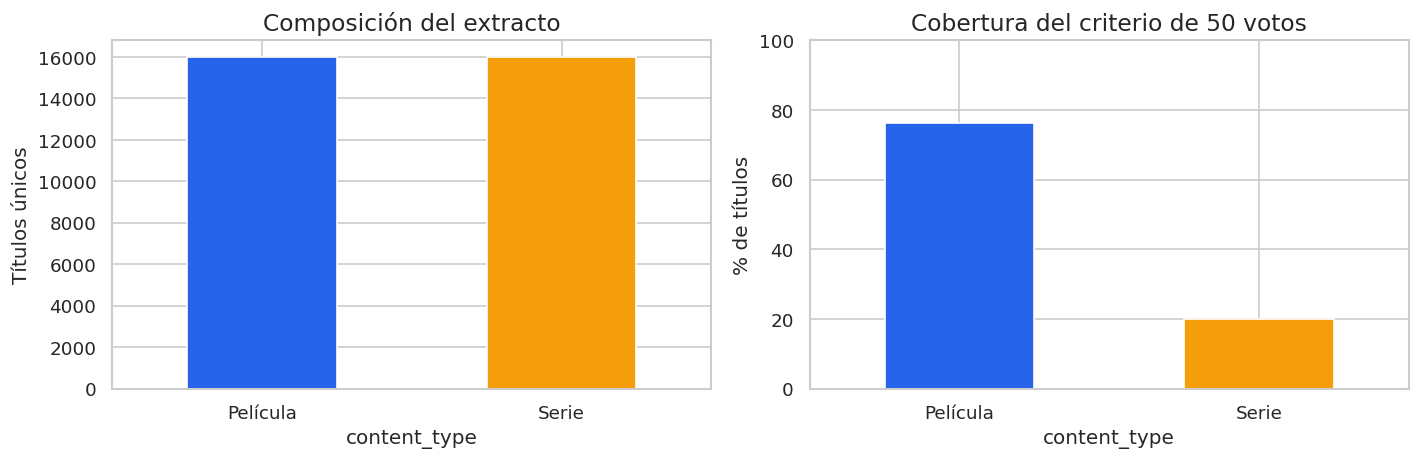

In [9]:
quality_clean=pd.DataFrame({'campo':df.columns,'tipo':df.dtypes.astype(str).values,
    'nulos':df.isna().sum().values,'% nulos':(df.isna().mean()*100).round(2).values,
    'distintos':df.nunique(dropna=True).values})
display(quality_clean)
coverage=df.groupby('content_type').agg(títulos=('content_id','nunique'),
    con_nota=('vote_average','count'),popularidad_media=('popularity','mean'),
    popularidad_mediana=('popularity','median'),nota_media_con_votos=('vote_average','mean'),
    votos_medianos=('vote_count','median'))
coverage['con_50_votos']=df[conf].groupby('content_type').size()
coverage['%_con_50_votos']=100*coverage.con_50_votos/coverage.títulos
coverage['nota_media_50_votos']=df[conf].groupby('content_type').vote_average.mean()
display(coverage.round(3))
display(df[['release_year','vote_average','vote_count','popularity']].describe(
    percentiles=[.01,.25,.5,.75,.95,.99]).T)
fig,axes=plt.subplots(1,2,figsize=(12,4))
df.content_type.value_counts().plot.bar(ax=axes[0],rot=0,color=[COLORS['Película'],COLORS['Serie']])
axes[0].set_title('Composición del extracto');axes[0].set_ylabel('Títulos únicos')
coverage['%_con_50_votos'].plot.bar(ax=axes[1],rot=0,color=[COLORS['Película'],COLORS['Serie']])
axes[1].set_title('Cobertura del criterio de 50 votos');axes[1].set_ylabel('% de títulos');axes[1].set_ylim(0,100)
plt.tight_layout();plt.show()


## 7. Géneros: volumen, popularidad y valoración (problema 2)

Diferenciamos el primer género de su presencia en cualquier otra posición. La homologación desglosa las categorías combinadas de series, entendiendo que estas asociaciones son una aproximación analítica documentada. Además, dividimos los rankings de popularidad por tipo y exigimos al menos 30 títulos por grupo para reducir el impacto de muestras muy pequeñas.


n  popularidad_media  popularidad_mediana  n_50_votos  nota_media_50_votos
content_type genre_main                                                                                    
Película     Action           1883             35.887               14.104        1528                6.242
             Adventure         381             32.148               14.327         318                6.431
             Animation        1117             28.910               13.996         861                7.021
             Comedy           2352             14.028                9.630        1982                6.170
             Crime             487             17.444               11.189         424                6.394
             Documentary       808             10.636                8.382         465                7.174
             Drama            3634             14.838               10.010        2676                6.620
             Family            359             21.237               12.161         278                6.653
             Fantasy           247             24.223               14.705         203                6.381
             History           125             16.986               11.290         109                6.662
             Horror           1520             22.523               11.244        1180                5.724
             Music             163             13.020                9.225         124                7.119
             Mystery           191             14.850               10.843         143                6.300
             Romance           914             23.708               11.262         516                6.550
             Science Fiction   416             27.458               14.448         347                6.075
             TV Movie          130              9.860                7.628          90                6.328
             Thriller          961             16.472               11.402         773                6.061
             War               144             19.109               12.464         118                6.731
             Western            61             15.837               11.578          49                6.078
Serie        Action            677             70.616               38.970         245                7.497
             Animation        1995             54.747               35.222         629                7.820
             Comedy           2329             62.940               34.839         516                7.359
             Crime             648             66.968               37.574         234                7.461
             Documentary       708             43.005               28.894          84                7.628
             Drama            5033             59.120               35.736         994                7.502
             Family            420             86.852               47.870          46                7.728
             Kids              226             63.370               39.598          13                7.400
             Mystery           322             46.976               31.632          94                7.310
             News               72             83.942               53.389           1                5.900
             Reality          1349             77.556               41.058          61                7.052
             Science Fiction   373             63.016               42.207         209                7.391
             Soap              339            169.715               84.644          49                7.527
             Talk              450            119.289               47.558          10                6.607
             War                64             50.298               36.896          12                7.188
             Western            12            102.563               30.769          10                7.421

,presencia_total,primer_género
Drama,14769,8667
Comedy,9105,4681
Action,5227,2560
Animation,4069,3112
Thriller,3769,961
Adventure,3756,381
Science Fiction,3412,789
Fantasy,3408,247
Crime,3203,1135
Family,3014,779


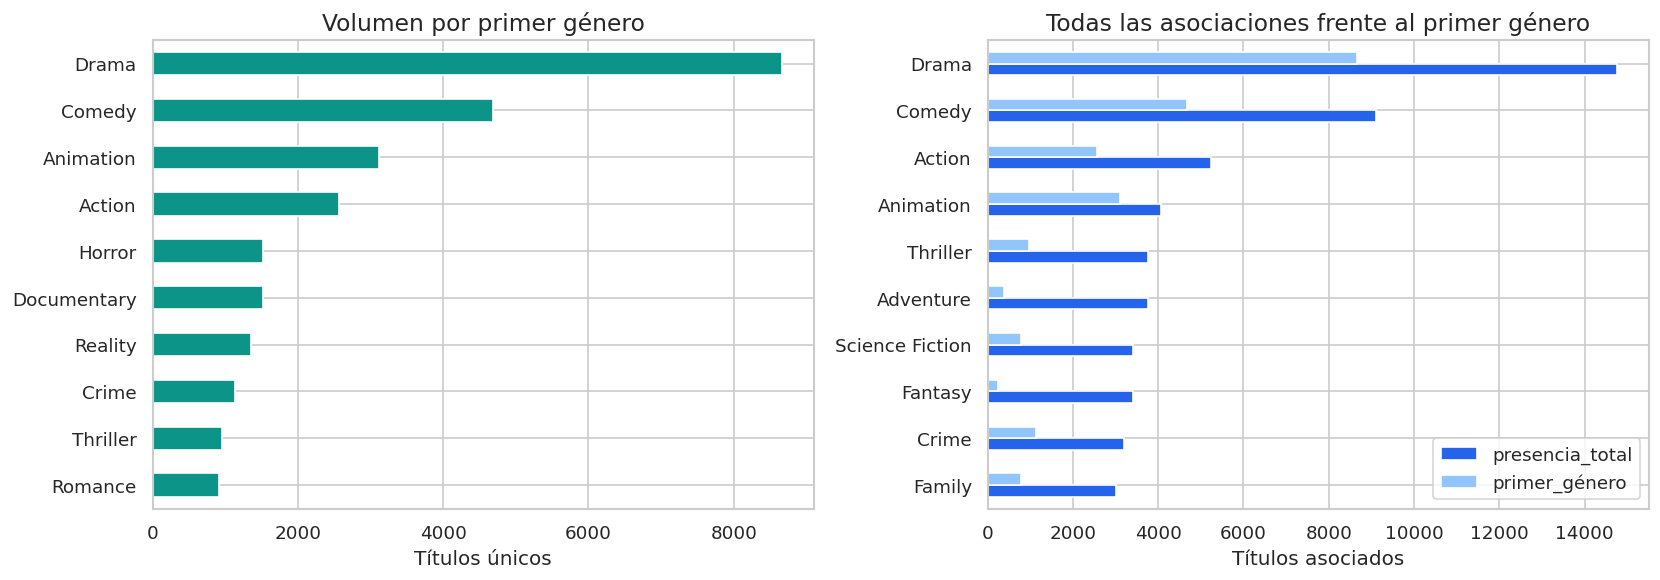

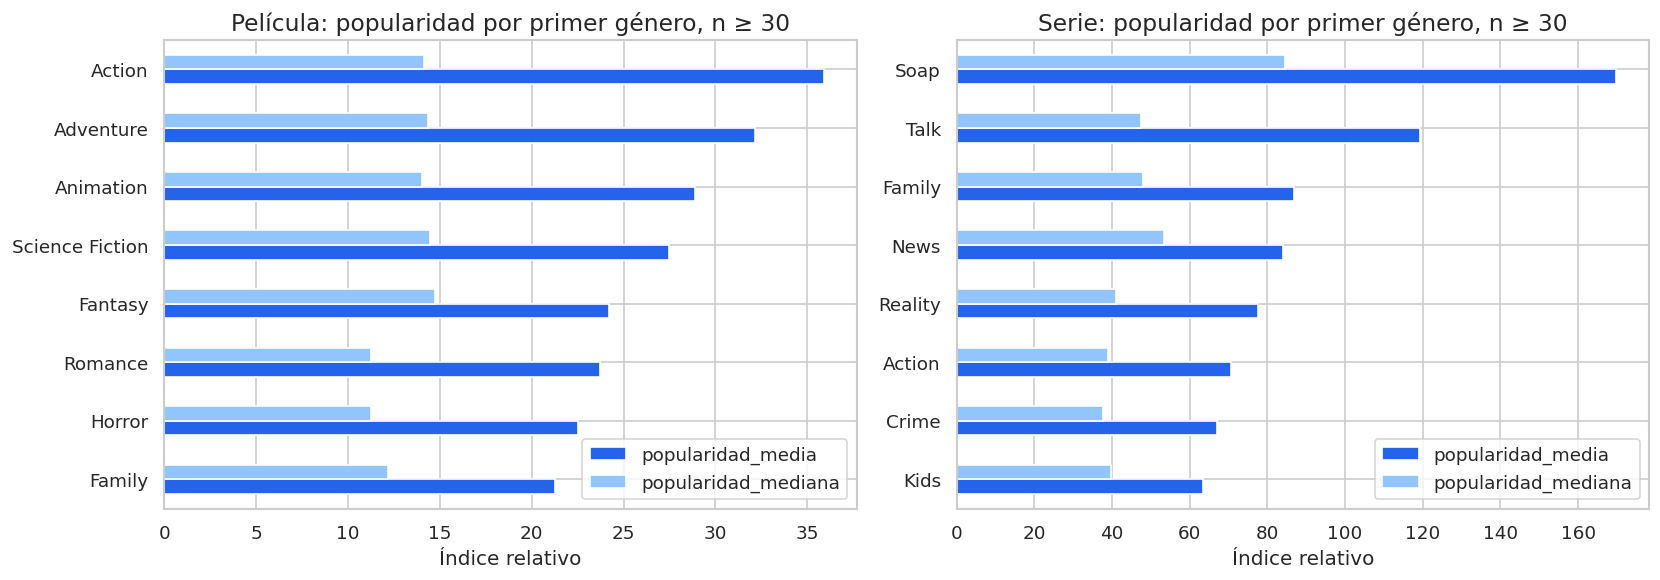

In [10]:
known=df[df.genre_main.ne('Sin información')]
genre_stats=known.groupby(['content_type','genre_main']).agg(n=('content_id','nunique'),
    popularidad_media=('popularity','mean'),popularidad_mediana=('popularity','median'))
genre_rating=known[known.es_confiable.eq(1)].groupby(['content_type','genre_main']).agg(
    n_50_votos=('content_id','nunique'),nota_media_50_votos=('vote_average','mean'))
genre_stats=genre_stats.join(genre_rating)
display(genre_stats.round(3))
genre_presence=pd.DataFrame({'presencia_total':pd.Series([g for l in gl for g in l if g!='Sin información']).value_counts(),
    'primer_género':known.genre_main.value_counts()}).fillna(0).astype(int).sort_values('presencia_total',ascending=False)
display(genre_presence)
fig,axes=plt.subplots(1,2,figsize=(14,5))
known.genre_main.value_counts().head(10).sort_values().plot.barh(ax=axes[0],color='#0D9488')
axes[0].set_title('Volumen por primer género');axes[0].set_xlabel('Títulos únicos')
genre_presence.head(10).sort_values('presencia_total').plot.barh(ax=axes[1],color=['#2563EB','#93C5FD'])
axes[1].set_title('Todas las asociaciones frente al primer género');axes[1].set_xlabel('Títulos asociados')
for ax in axes:ax.set_ylabel('')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,kind in zip(axes,['Película','Serie']):
    g=genre_stats.xs(kind).query('n >= @MIN_GROUP').nlargest(8,'popularidad_media')
    g[['popularidad_media','popularidad_mediana']].iloc[::-1].plot.barh(ax=ax,color=['#2563EB','#93C5FD'])
    ax.set_title(f'{kind}: popularidad por primer género, n ≥ {MIN_GROUP}')
    ax.set_xlabel('Índice relativo');ax.set_ylabel('')
plt.tight_layout();plt.show()


## 8. Países, coproducciones e idiomas

Un mapa de `country_iso2` solo representa producciones de un país. Los registros `ZZ` se excluyen: no tienen una ubicación única. La participación total por país se calcula temporalmente con la lista completa y no debe confundirse con la variable de país único.


Países participantes: 147 | países con producciones de un solo país: 100
Registros no localizables como país único: 7625
El idioma original no informa el país de la audiencia ni los doblajes disponibles.


,participación_total,producciones_un_país
United States,10955,7760
Japan,2869,2585
United Kingdom,2608,1105
China,2399,2004
South Korea,2174,1999
France,2108,855
Canada,1715,737
Germany,1160,554
India,912,771
Spain,822,470


,títulos
tipo_produccion,
Un solo país,24366
Coproducción,5364
Sin información,2261


,n,popularidad_media,popularidad_mediana
language,,,
English,13969,38.839,17.029
Chinese,2834,38.718,29.468
Japanese,2784,38.727,24.286
Korean,2240,44.903,25.770
Spanish,1646,57.685,27.440
French,1639,39.045,12.159
German,730,44.388,25.462
Hindi,635,60.335,24.509
Tagalog,525,69.636,52.053


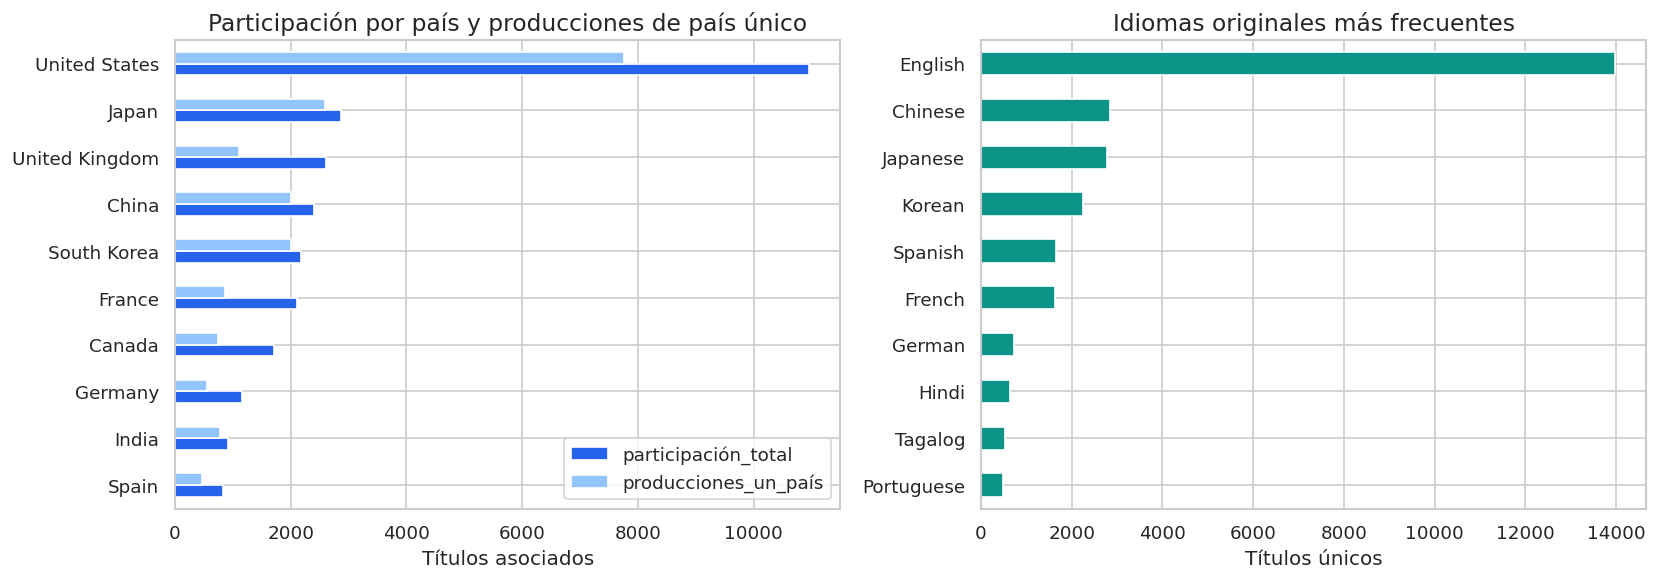

In [11]:
single=df[df.tipo_produccion.eq('Un solo país')]
country_presence=pd.DataFrame({'participación_total':pd.Series([c for l in cl for c in l]).value_counts(),
    'producciones_un_país':single.country_main.value_counts()}).fillna(0).astype(int).sort_values('participación_total',ascending=False)
display(country_presence.head(20))
display(df.tipo_produccion.value_counts().rename('títulos').to_frame())
language_stats=df.groupby('language').agg(n=('content_id','nunique'),
    popularidad_media=('popularity','mean'),popularidad_mediana=('popularity','median')).sort_values('n',ascending=False)
display(language_stats.head(20).round(3))
fig,axes=plt.subplots(1,2,figsize=(14,5))
country_presence.head(10).sort_values('participación_total').plot.barh(ax=axes[0],color=['#2563EB','#93C5FD'])
axes[0].set_title('Participación por país y producciones de país único');axes[0].set_xlabel('Títulos asociados')
language_stats.head(10).n.iloc[::-1].plot.barh(ax=axes[1],color='#0D9488')
axes[1].set_title('Idiomas originales más frecuentes');axes[1].set_xlabel('Títulos únicos')
for ax in axes:ax.set_ylabel('')
plt.tight_layout();plt.show()
print('Países participantes:',len(country_presence),'| países con producciones de un solo país:',single.country_main.nunique())
print('Registros no localizables como país único:',df.country_iso2.eq('ZZ').sum())
print('El idioma original no informa el país de la audiencia ni los doblajes disponibles.')


## 9. Distribuciones, valores extremos y cantidad de votos

La popularidad y los votos tienen colas largas. Se muestran transformaciones logarítmicas y medianas para no ocultar el comportamiento de la mayoría. Los extremos se conservan; el criterio IQR es una señal de inspección, no un certificado de error.


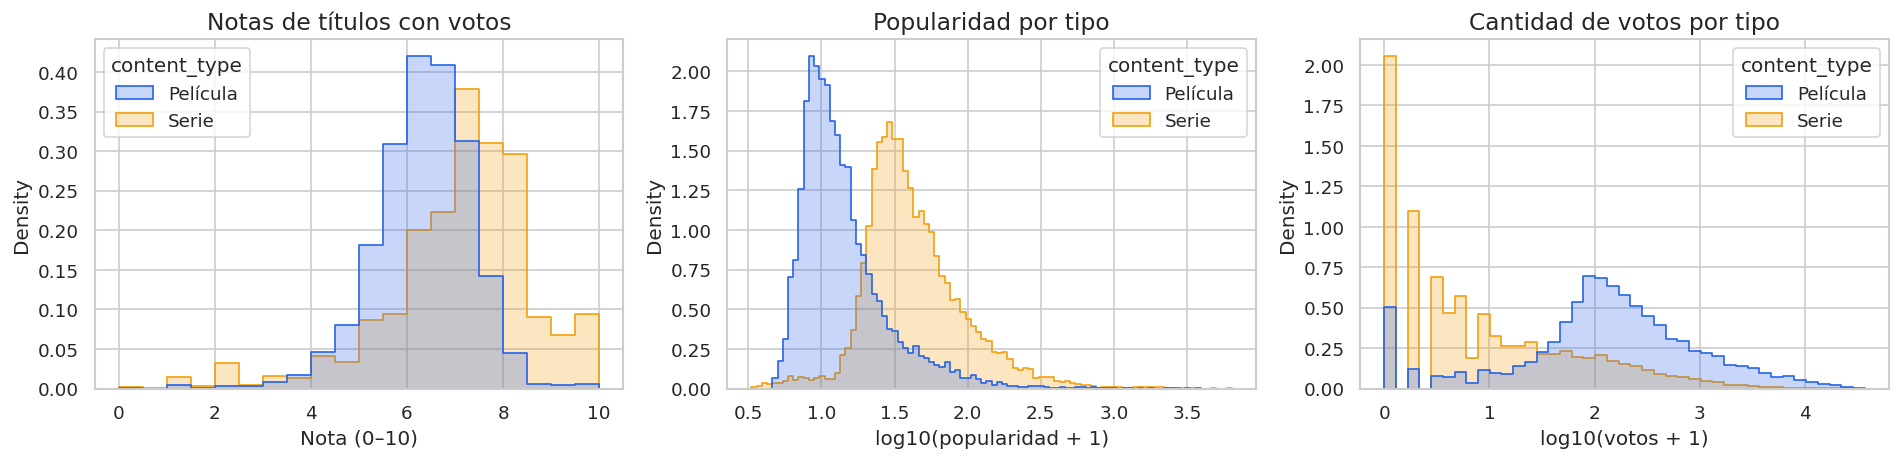

,n,mínimo,máximo
rating_band,,,
0 a <5,2222,0.0,4.995
5 a <6,4813,5.0,5.997
6 a <7,8874,6.0,6.999
7 a <8,7678,7.0,7.997
8 a 10,3844,8.0,10.000
Sin calificación,4560,NaN,NaN


rating_confiable,No,Sí
content_type,,
Película,3815,12185
Serie,12779,3212


,tipo,variable,n,q1,q3,extremos_IQR,acción
0,Película,popularity,16000,7.841,17.336,1705,Conservar e inspeccionar
1,Película,vote_count,16000,53.000,422.000,2287,Conservar e inspeccionar
2,Película,vote_average,15106,5.726,7.000,328,Conservar e inspeccionar
3,Serie,popularity,15991,24.898,62.217,1609,Conservar e inspeccionar
4,Serie,vote_count,15991,1.000,30.000,2661,Conservar e inspeccionar
5,Serie,vote_average,12325,6.300,8.000,510,Conservar e inspeccionar


In [12]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
sns.histplot(data=df,x='vote_average',hue='content_type',bins=np.linspace(0,10,21),
    stat='density',common_norm=False,element='step',palette=COLORS,ax=axes[0])
axes[0].set_title('Notas de títulos con votos');axes[0].set_xlabel('Nota (0–10)')
sns.histplot(data=df.assign(log_pop=np.log10(df.popularity+1)),x='log_pop',hue='content_type',
    stat='density',common_norm=False,element='step',palette=COLORS,ax=axes[1])
axes[1].set_title('Popularidad por tipo');axes[1].set_xlabel('log10(popularidad + 1)')
sns.histplot(data=df.assign(log_votes=np.log10(df.vote_count+1)),x='log_votes',hue='content_type',
    stat='density',common_norm=False,element='step',palette=COLORS,ax=axes[2])
axes[2].set_title('Cantidad de votos por tipo');axes[2].set_xlabel('log10(votos + 1)')
plt.tight_layout();plt.show()
display(df.groupby('rating_band').agg(n=('content_id','size'),mínimo=('vote_average','min'),máximo=('vote_average','max')))
display(pd.crosstab(df.content_type,df.rating_confiable))
outlier_rows=[]
for kind,d in df.groupby('content_type'):
    for c in ['popularity','vote_count','vote_average']:
        s=d[c].dropna();q1,q3=s.quantile([.25,.75]);iqr=q3-q1
        outlier_rows.append({'tipo':kind,'variable':c,'n':len(s),'q1':q1,'q3':q3,
            'extremos_IQR':int(((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum()),'acción':'Conservar e inspeccionar'})
display(pd.DataFrame(outlier_rows).round(3))


## 10. Popularidad y valoración: relaciones y cuadrantes (problema 6)

Las medianas se calculan dentro de cada tipo y en títulos con 50 votos. «Alta» y «baja» indican posición relativa frente a esas medianas, no calidad absoluta. La correlación no demuestra causa ni mide consumo de usuarios de StreamView.


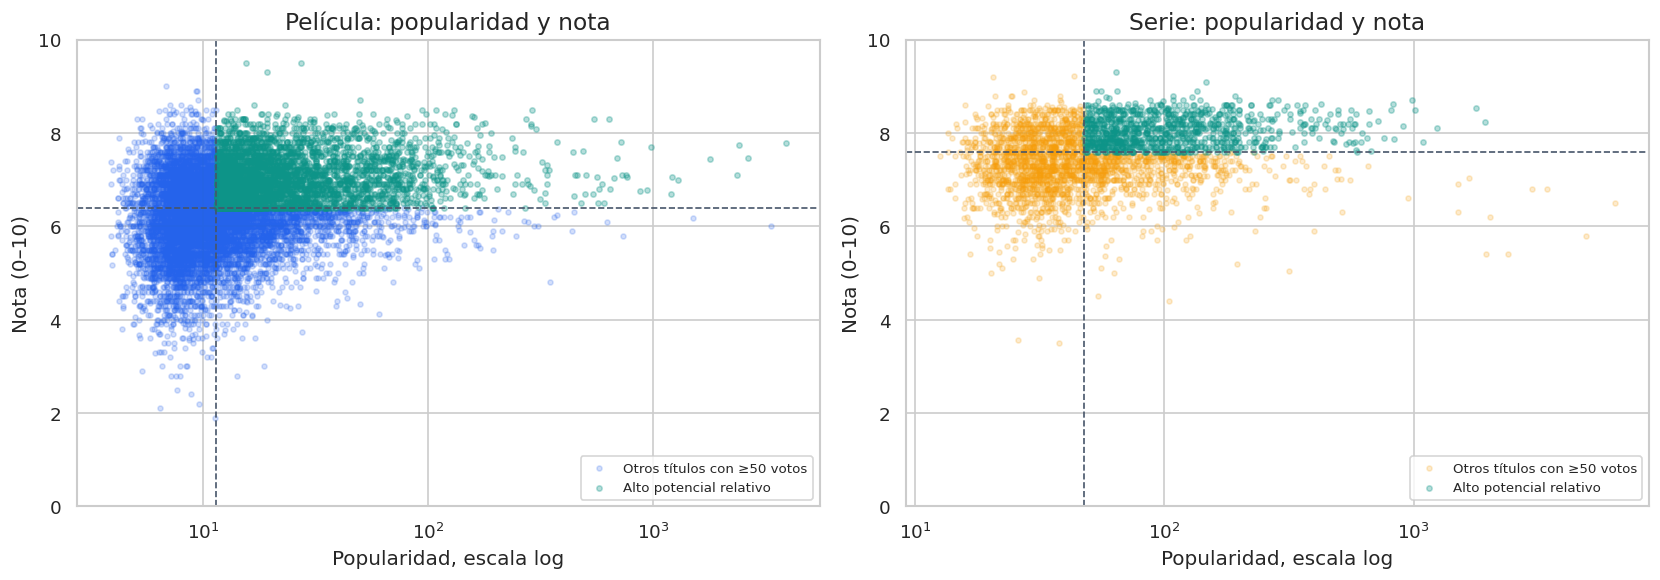

,tipo,n,Pearson_popularidad_nota,Spearman_popularidad_nota,Spearman_popularidad_votos
0,Película,12185,0.0922,0.2422,0.6044
1,Serie,3212,0.0129,0.2515,0.3682


content_type,Película,Serie
cuadrante,,
Alta calificación y alta popularidad,3709,953
Alta calificación y baja popularidad,2758,653
Baja calificación y alta popularidad,2385,653
Baja calificación y baja popularidad,3333,953
Sin calificación confiable,3815,12779


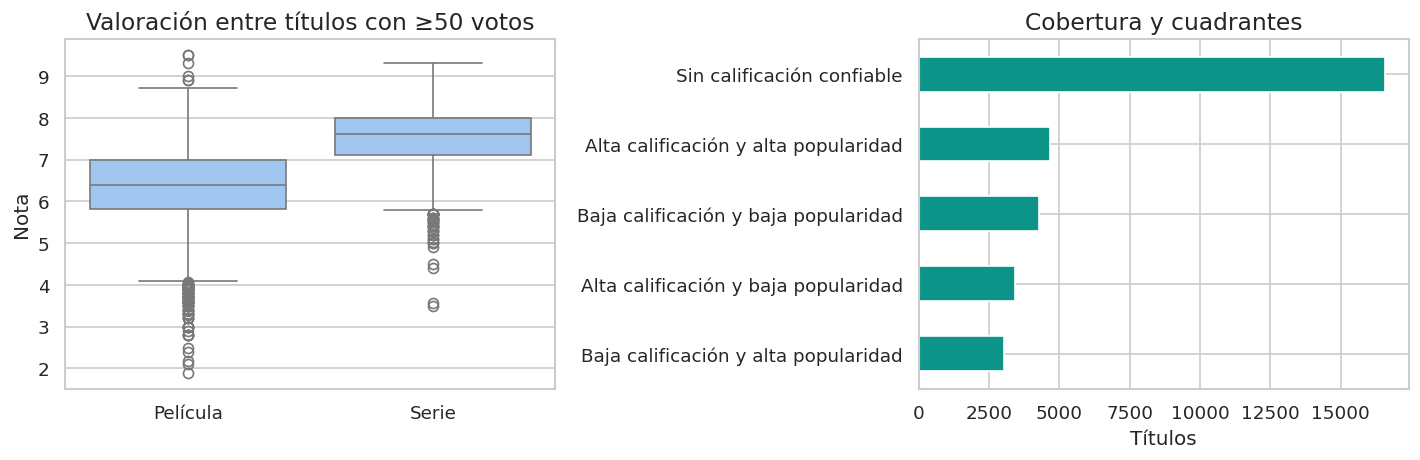

In [13]:
rated=df[df.es_confiable.eq(1)].copy()
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,kind in zip(axes,['Película','Serie']):
    d=rated[rated.content_type.eq(kind)]
    low=d[d.es_alto_potencial.eq(0)]; high=d[d.es_alto_potencial.eq(1)]
    ax.scatter(low.popularity,low.vote_average,s=9,alpha=.2,color=COLORS[kind],label='Otros títulos con ≥50 votos')
    ax.scatter(high.popularity,high.vote_average,s=10,alpha=.3,color='#0D9488',label='Alto potencial relativo')
    ax.axhline(umbrales.loc[kind,'mediana_calificacion'],color='#475569',ls='--',lw=1)
    ax.axvline(umbrales.loc[kind,'mediana_popularidad'],color='#475569',ls='--',lw=1)
    ax.set_xscale('log');ax.set_ylim(0,10);ax.set_title(f'{kind}: popularidad y nota')
    ax.set_xlabel('Popularidad, escala log');ax.set_ylabel('Nota (0–10)');ax.legend(fontsize=8,loc='lower right')
plt.tight_layout();plt.show()
relations=[]
def spearman_pair(a,b):
    p=pd.DataFrame({'a':a,'b':b}).dropna()
    return p.a.rank().corr(p.b.rank())
for kind,d in rated.groupby('content_type'):
    relations.append({'tipo':kind,'n':len(d),'Pearson_popularidad_nota':d.popularity.corr(d.vote_average),
        'Spearman_popularidad_nota':spearman_pair(d.popularity,d.vote_average),
        'Spearman_popularidad_votos':spearman_pair(d.popularity,d.vote_count)})
display(pd.DataFrame(relations).round(4))
display(pd.crosstab(df.cuadrante,df.content_type))
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=rated,x='content_type',y='vote_average',color='#93C5FD',ax=axes[0])
axes[0].set_title('Valoración entre títulos con ≥50 votos');axes[0].set_xlabel('');axes[0].set_ylabel('Nota')
df.groupby('cuadrante').size().sort_values().plot.barh(ax=axes[1],color='#0D9488')
axes[1].set_title('Cobertura y cuadrantes');axes[1].set_xlabel('Títulos');axes[1].set_ylabel('')
plt.tight_layout();plt.show()


## 11. Características de contenidos de alto potencial

Se compara la proporción de destacados dentro de cada grupo para no recomendar únicamente los géneros más numerosos. Se muestran denominadores y se restringen los rankings a grupos con al menos 30 títulos. Los países describen producción y no demanda del mercado.


País único o coproducción entre destacados:
Idiomas entre destacados:
Títulos destacados para explorar, no recomendaciones automáticas de compra:


n  destacados  n_50_votos  %_del_grupo  %_entre_50_votos
content_type genre_main                                                                  
Película     Animation        1117         528         861       47.269            61.324
             War               144          61         118       42.361            51.695
             History           125          49         109       39.200            44.954
             Family            359         130         278       36.212            46.763
             Adventure         381         129         318       33.858            40.566
             Fantasy           247          78         203       31.579            38.424
             Action           1883         548        1528       29.102            35.864
             Crime             487         134         424       27.515            31.604
             Western            61          16          49       26.230            32.653
             Science Fiction   416         100         347       24.038            28.818
             Drama            3634         838        2676       23.060            31.315
             Romance           914         178         516       19.475            34.496
             Mystery           191          36         143       18.848            25.175
             Thriller          961         179         773       18.626            23.157
             Music             163          29         124       17.791            23.387
Serie        Science Fiction   373          63         209       16.890            30.144
Película     Comedy           2352         376        1982       15.986            18.971
             Horror           1520         195        1180       12.829            16.525
Serie        Action            677          80         245       11.817            32.653
Película     Documentary       808          95         465       11.757            20.430

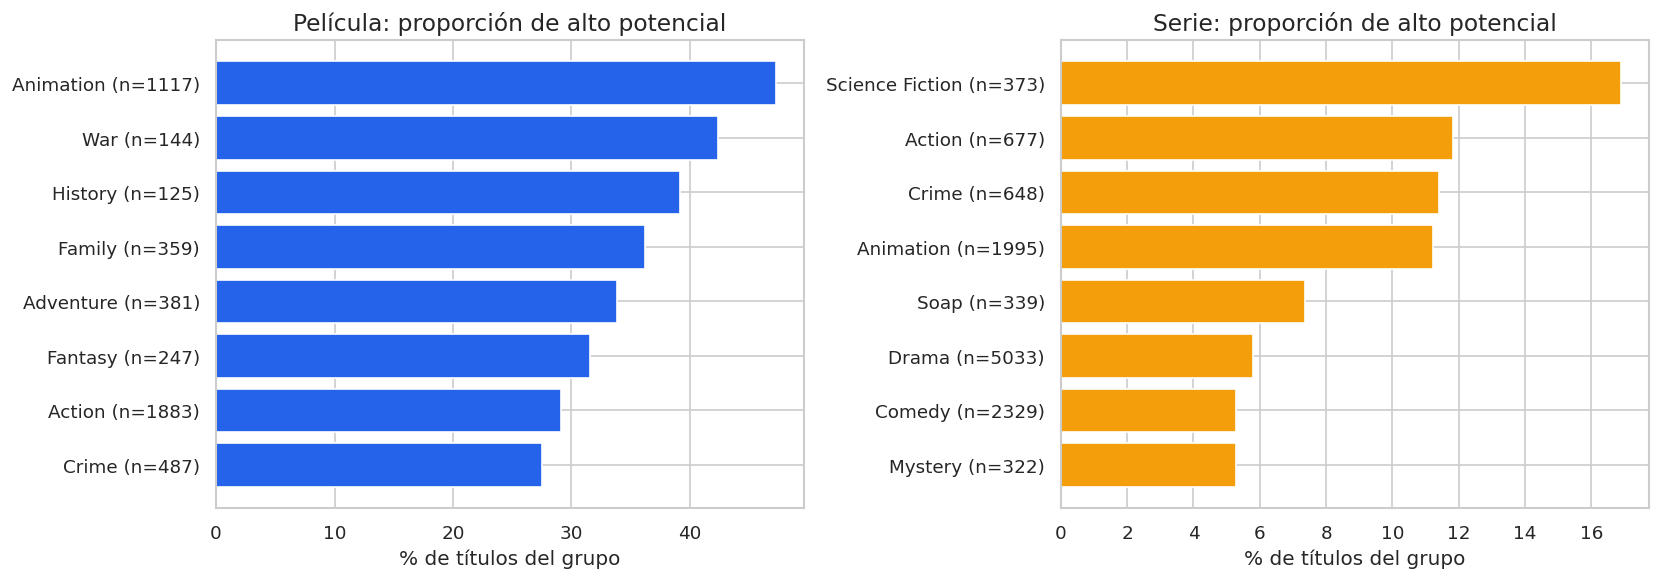

,títulos
country_main,
United States,1814
Coproducción internacional,1354
Japan,462
South Korea,249
United Kingdom,108
Mexico,73
France,70
Spain,63
China,61


,títulos
language,
English,2935
Japanese,493
Spanish,263
Korean,262
French,155
Chinese,105
German,52
Italian,45
Russian,42


,title_label,content_type,genre_main,country_main,language,vote_average,vote_count,popularity
7103,Nude (2017),Película,Documentary,United States,English,9.500,161,27.026
14763,Succubus (2024) [M1130276],Película,Horror,United States,English,9.500,157,15.457
13392,Kill Shot (2023),Película,Action,United States,English,9.300,158,19.092
30139,Wizards Beyond Waverly Place (2024),Serie,Comedy,United States,English,9.300,68,63.697
29032,Pokémon Horizons (2023),Serie,Science Fiction,Japan,Japanese,9.100,77,147.408
29246,Adventure Time: Fionna & Cake (2023),Serie,Animation,United States,English,8.900,208,53.227
29198,The Good Bad Mother (2023),Serie,Drama,South Korea,Korean,8.900,149,64.362
21122,Nirvana in Fire (2015),Serie,Drama,China,Chinese,8.900,56,135.613
29167,Twinkling Watermelon (2023),Serie,Science Fiction,South Korea,Korean,8.897,73,55.894
27017,Arcane (2021),Serie,Animation,Coproducción internacional,English,8.800,4932,191.815


In [14]:
potential=df[df.es_alto_potencial.eq(1)]
potential_genre=known.groupby(['content_type','genre_main']).agg(n=('content_id','nunique'),
    destacados=('es_alto_potencial','sum'),n_50_votos=('es_confiable','sum'))
potential_genre['%_del_grupo']=100*potential_genre.destacados/potential_genre.n
potential_genre['%_entre_50_votos']=100*potential_genre.destacados/potential_genre.n_50_votos.replace(0,np.nan)
display(potential_genre[potential_genre.n.ge(MIN_GROUP)].sort_values('%_del_grupo',ascending=False).head(20).round(3))
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,kind in zip(axes,['Película','Serie']):
    p=potential_genre.xs(kind).query('n >= @MIN_GROUP').nlargest(8,'%_del_grupo')
    labels=[f'{idx} (n={int(row.n)})' for idx,row in p.iterrows()]
    ax.barh(labels[::-1],p['%_del_grupo'].iloc[::-1],color=COLORS[kind])
    ax.set_title(f'{kind}: proporción de alto potencial');ax.set_xlabel('% de títulos del grupo')
plt.tight_layout();plt.show()
print('País único o coproducción entre destacados:')
display(potential.groupby('country_main').size().sort_values(ascending=False).head(15).rename('títulos').to_frame())
print('Idiomas entre destacados:')
display(potential.language.value_counts().head(15).rename('títulos').to_frame())
print('Títulos destacados para explorar, no recomendaciones automáticas de compra:')
display(potential.sort_values(['vote_average','vote_count'],ascending=False).head(15)[
    ['title_label','content_type','genre_main','country_main','language','vote_average','vote_count','popularity']])


## 12. Rankings y producción: directores y reparto

Los rankings de nota usan al menos 50 votos y muestran el número de evaluaciones. Las listas de personas se separan por el delimitador de la fuente; los conteos son asociaciones a títulos, no una medida de impacto artístico. Los nombres homónimos no se resuelven con estos datos.


Película — top por popularidad
Película — top por valoración con ≥50 votos
Serie — top por popularidad
Serie — top por valoración con ≥50 votos


,title_label,genre_main,popularity,vote_average,vote_count,rating_confiable
15000,The Gorge (2025),Romance,3876.006,7.785,1572,Sí
15001,Flight Risk (2025),Action,3320.616,6.000,350,Sí
14000,Mufasa: The Lion King (2024),Adventure,2643.627,7.467,1497,Sí
14001,Sonic the Hedgehog 3 (2024),Action,2402.503,7.742,2047,Sí
14002,Moana 2 (2024),Animation,2347.007,7.100,1758,Sí
14003,Amaran (2024),Action,1780.289,7.440,175,Sí
15002,Captain America: Brave New World (2025),Action,1495.724,6.179,833,Sí
15003,Companion (2025),Horror,1283.362,7.000,610,Sí
14004,Panda Plan (2024),Action,1214.508,7.055,146,Sí
14005,Kraven the Hunter (2024),Action,1195.885,6.700,1333,Sí


,title_label,genre_main,vote_average,vote_count,popularity
7103,Nude (2017),Documentary,9.5,161,27.026
14763,Succubus (2024) [M1130276],Horror,9.5,157,15.457
13392,Kill Shot (2023),Action,9.3,158,19.092
10878,Break the Silence: The Movie (2020),Music,9.0,183,6.845
10601,The Three Deaths of Marisela Escobedo (2020),Documentary,8.9,228,9.243
12784,BTS: Permission to Dance on Stage - LA (2022),Music,8.9,157,9.365
12060,Selena Gomez: My Mind & Me (2022),Documentary,8.7,451,49.461
9645,My First Client (2019),Drama,8.7,86,9.505
1496,Lady Gaga Presents: The Monster Ball Tour at Madison Square Garden (2011),Music,8.6,99,7.960
3689,Stranger Things (2013),Drama,8.6,67,7.095


,title_label,genre_main,popularity,vote_average,vote_count,rating_confiable
21000,The Late Show with Stephen Colbert (2015),Comedy,6421.923,6.493,288,Sí
20000,The Tonight Show Starring Jimmy Fallon (2014),Comedy,4925.253,5.800,321,Sí
18000,Good Mythical Morning (2012),Comedy,3414.466,6.800,67,Sí
24000,Chronicles of the Sun (2018),Soap,2987.485,6.800,117,Sí
30000,Volta por Cima (2024),Soap,2885.720,5.781,16,No
30001,She's the One (2024),Soap,2862.872,8.100,9,No
30004,Crazy About You (2024),Soap,2442.243,5.200,16,No
30002,La Casa de los Famosos Colombia (2024),Reality,2398.165,6.600,27,No
20001,Late Night with Seth Meyers (2014),Talk,2395.016,5.400,98,Sí
25000,GH dúo (2019),Reality,2379.884,6.500,4,No


,title_label,genre_main,vote_average,vote_count,popularity
30139,Wizards Beyond Waverly Place (2024),Comedy,9.300,68,63.697
29346,When I Fly Towards You (2023),Drama,9.230,50,43.392
26975,Selena + Chef (2020),Reality,9.200,50,20.473
29032,Pokémon Horizons (2023),Science Fiction,9.100,77,147.408
29246,Adventure Time: Fionna & Cake (2023),Animation,8.900,208,53.227
29198,The Good Bad Mother (2023),Drama,8.900,149,64.362
21122,Nirvana in Fire (2015),Drama,8.900,56,135.613
29167,Twinkling Watermelon (2023),Science Fiction,8.897,73,55.894
29816,The Boy's Word: Blood on the Asphalt (2023),Drama,8.887,182,27.448
27017,Arcane (2021),Animation,8.800,4932,191.815


,títulos
person,
Don Michael Perez,21
Dominic Zapata,21
Tyler Perry,20
Sam Liu,18
Gil Tejada Jr.,17
Roel Reiné,15
Steven Soderbergh,15
Ricky Davao,15
Sean McNamara,15


,títulos
person,
Min Do-yoon,111
Kana Hanazawa,97
Yuki Kaji,69
Grey DeLisle,65
Takahiro Sakurai,63
Natsuki Hanae,63
Yuichi Nakamura,63
Yoko Hikasa,62
Saori Hayami,59


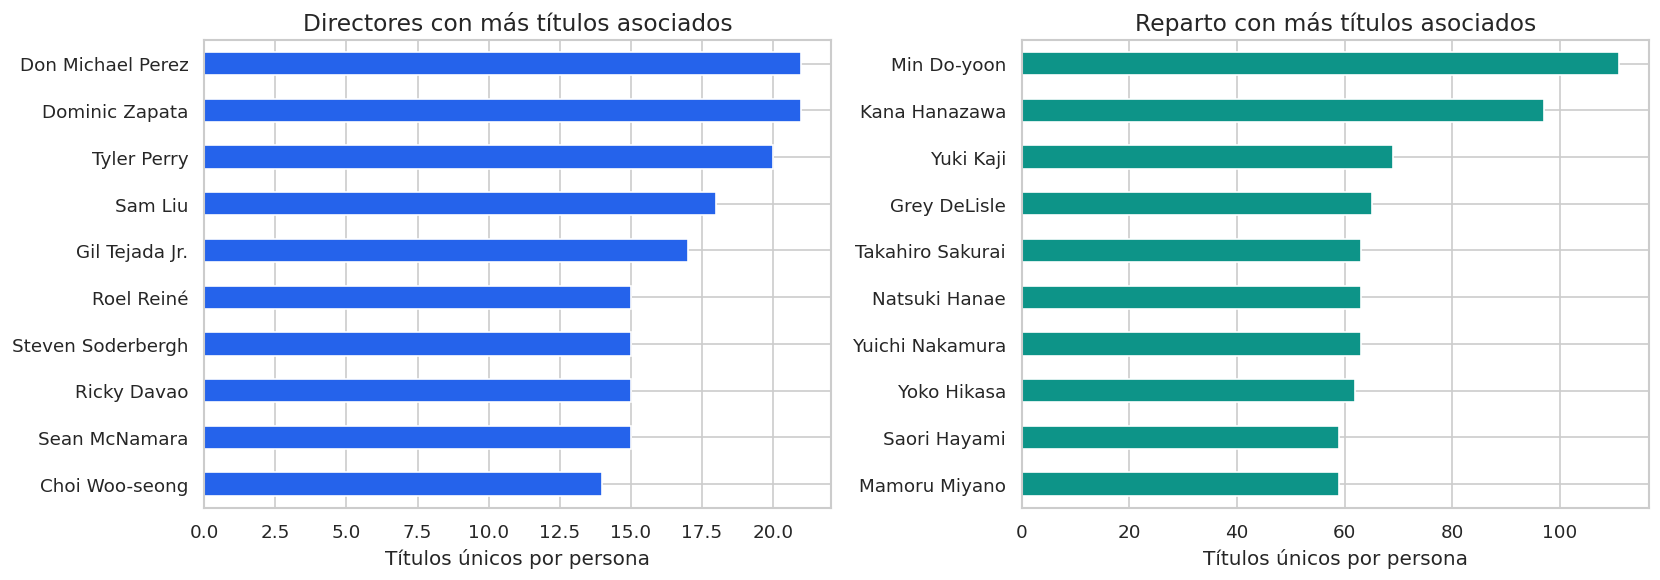

In [15]:
for kind in ['Película','Serie']:
    print(kind,'— top por popularidad')
    display(df[df.content_type.eq(kind)].nlargest(10,'popularity')[
        ['title_label','genre_main','popularity','vote_average','vote_count','rating_confiable']])
    print(kind,'— top por valoración con ≥50 votos')
    display(rated[rated.content_type.eq(kind)].sort_values(['vote_average','vote_count'],ascending=False).head(10)[
        ['title_label','genre_main','vote_average','vote_count','popularity']])
def count_people(col):
    links=df[['content_id',col]].assign(person=lambda x:x[col].str.split(',')).explode('person')
    links['person']=links.person.str.strip()
    links=links[links.person.notna()&~links.person.isin(['','Sin información'])]
    return links.drop_duplicates(['content_id','person']).groupby('person').content_id.nunique().sort_values(ascending=False)
directors=count_people('director');actors=count_people('cast')
display(directors.head(15).rename('títulos').to_frame());display(actors.head(15).rename('títulos').to_frame())
fig,axes=plt.subplots(1,2,figsize=(14,5))
directors.head(10).iloc[::-1].plot.barh(ax=axes[0],color='#2563EB')
actors.head(10).iloc[::-1].plot.barh(ax=axes[1],color='#0D9488')
axes[0].set_title('Directores con más títulos asociados');axes[1].set_title('Reparto con más títulos asociados')
for ax in axes:ax.set_xlabel('Títulos únicos por persona');ax.set_ylabel('')
plt.tight_layout();plt.show()


## 13. Comparación por año de estreno

Las líneas de notas y las áreas de popularidad comparan contenidos de distintos años de estreno con las métricas disponibles en la extracción. No son series históricas de consumo ni de cambios de popularidad del mismo contenido. El patrón de cupos impide medir crecimiento del catálogo.


2020–2025 abarca seis años; no comparar totales como si todos los períodos duraran cinco.


content_type,Película,Serie
release_year,,
2010,6.249,7.561
2011,6.225,7.471
2012,6.197,7.371
2013,6.281,7.462
2014,6.264,7.443
2015,6.260,7.445
2016,6.321,7.367
2017,6.379,7.431
2018,6.425,7.625


content_type,Película,Serie
release_year,,
2010,7.682,32.392
2011,7.920,36.972
2012,8.888,36.201
2013,9.354,40.218
2014,10.334,36.518
2015,9.559,41.852
2016,10.309,43.015
2017,11.090,42.848
2018,10.986,46.755


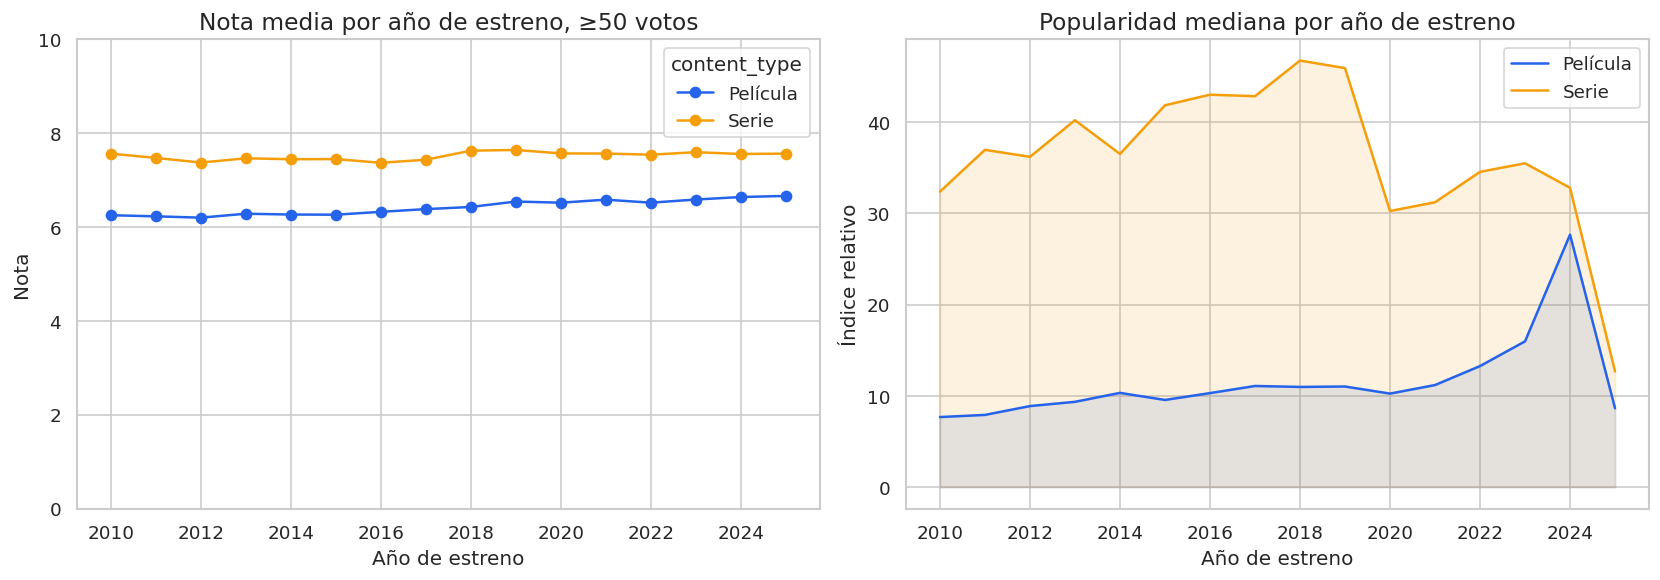

,títulos,años
release_period,,
2010-2014,10000,5
2015-2019,10000,5
2020-2025,11991,6


In [16]:
year_rating=rated.groupby(['release_year','content_type']).vote_average.mean().unstack()
year_pop=df.groupby(['release_year','content_type']).popularity.median().unstack()
display(year_rating.round(3));display(year_pop.round(3))
fig,axes=plt.subplots(1,2,figsize=(14,5))
year_rating.plot(ax=axes[0],marker='o',color=[COLORS['Película'],COLORS['Serie']])
axes[0].set_title('Nota media por año de estreno, ≥50 votos');axes[0].set_ylabel('Nota');axes[0].set_ylim(0,10)
for kind in ['Película','Serie']:
    axes[1].fill_between(year_pop.index,year_pop[kind],alpha=.13,color=COLORS[kind])
    axes[1].plot(year_pop.index,year_pop[kind],color=COLORS[kind],label=kind)
axes[1].set_title('Popularidad mediana por año de estreno');axes[1].set_ylabel('Índice relativo');axes[1].legend()
for ax in axes:ax.set_xlabel('Año de estreno')
plt.tight_layout();plt.show()
display(df.groupby('release_period').agg(títulos=('content_id','size'),años=('release_period_years','first')))
print('2020–2025 abarca seis años; no comparar totales como si todos los períodos duraran cinco.')


## 14. Finanzas: cobertura, relaciones y sensibilidad

Los ingresos y el presupuesto reflejan la producción cinematográfica, no suscripciones ni compras de licencias. Es importante notar que el ratio individual y el ratio de sumas responden a preguntas distintas; por eso, para el ratio agregado usamos el mismo conjunto de películas tanto en el numerador como en el denominador.

Conservamos los importes bajos y comparamos el resultado con el subconjunto que no tiene esa marca. Este análisis de sensibilidad no busca demostrar si un grupo está bien y el otro mal, sino mostrar qué tan sensibles son los resultados a aquellos datos que requieren revisión.


Cobertura: 3,540 de 16,000 películas (22.125%).
Asociación presupuesto-ingresos: Pearson= 0.7479 Spearman= 0.7099 n= 3540


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
budget,3540.0,3.558214e+07,5.118602e+07,1.000000e+00,6.756000e+04,5.903050e+06,1.500000e+07,4.000000e+07,1.551400e+08,2.280500e+08,4.600000e+08
revenue,3540.0,1.037772e+08,2.178201e+08,2.000000e+00,8.122850e+03,4.207730e+06,2.380000e+07,9.509302e+07,4.988921e+08,1.077081e+09,2.799439e+09
profit,3540.0,6.819510e+07,1.827271e+08,-1.995460e+08,-6.402180e+07,-3.503000e+06,7.273240e+06,5.677611e+07,3.805215e+08,9.026265e+08,2.443439e+09
ratio_exact,3540.0,7.815457e+02,4.155657e+04,7.800000e-06,2.276076e-03,5.213043e-01,1.700033e+00,3.760963e+00,1.181960e+01,3.733730e+01,2.456760e+06


,alcance,películas,presupuesto_total_USD,ingresos_total_USD,ratio_de_totales,ratio_individual_mediano,ratio_individual_medio
0,Ambas cifras positivas,3540,125960767278,367371433138,2.916554,1.700033,781.545657
1,Sin bandera de importe bajo,3492,125628417074,367355105933,2.924140,1.719631,4.230729


,películas
resultado,
Ingresos superiores al presupuesto,2236
Ingresos inferiores al presupuesto,1298
Equilibrio,6


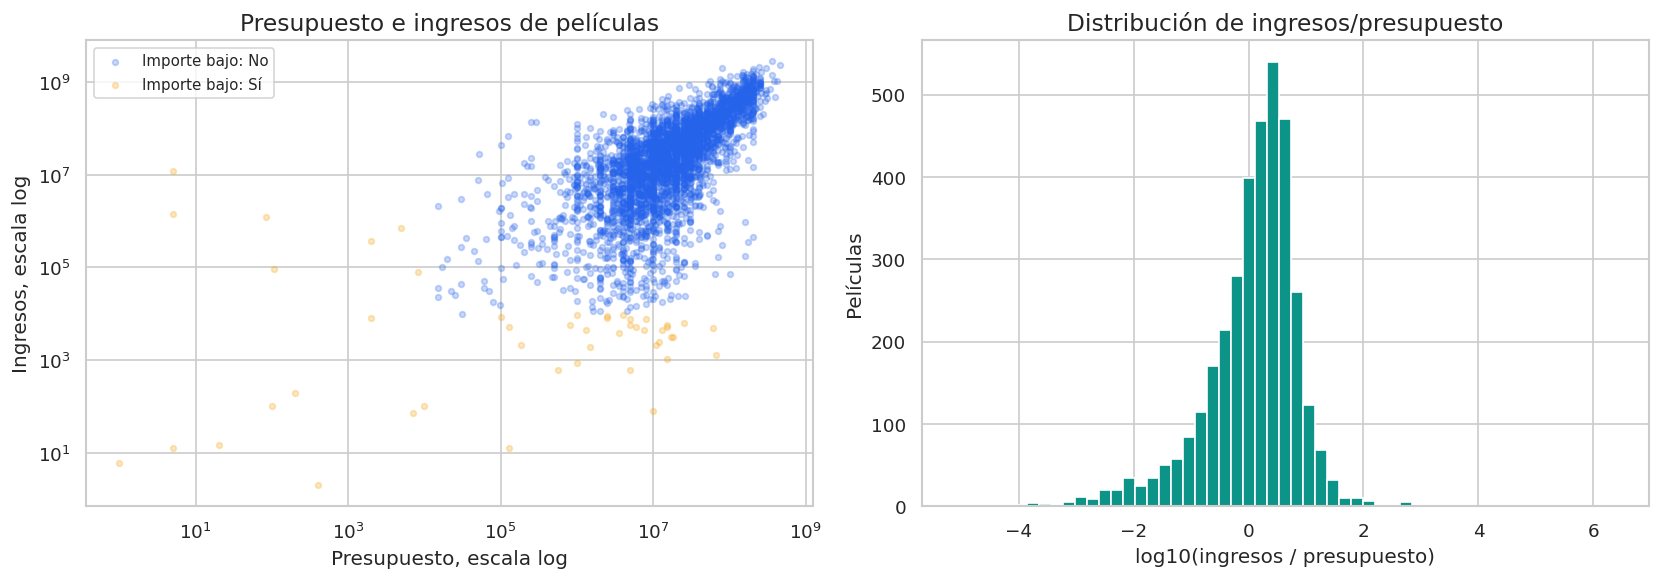

,title_label,budget,revenue,ratio_exact,monto_financiero_revisar
9001,Avengers: Endgame (2019),356000000,2799439100,7.863593,No
12006,Avatar: The Way of Water (2022),460000000,2320250281,5.044022,No
5010,Star Wars: The Force Awakens (2015),245000000,2068223624,8.441729,No
8000,Avengers: Infinity War (2018),300000000,2052415039,6.841383,No
15019,Ne Zha 2 (2025),80000000,1990000000,24.875000,No
11000,Spider-Man: No Way Home (2021),200000000,1921847111,9.609236,No
14026,Inside Out 2 (2024),200000000,1698863816,8.494319,No
5001,Jurassic World (2015),150000000,1671537444,11.143583,No
9000,The Lion King (2019),260000000,1662020819,6.392388,No
2000,The Avengers (2012),220000000,1518815515,6.903707,No


,title_label,budget,revenue,ratio_exact,monto_financiero_revisar,financiero_atipico
6269,The Beatles: Eight Days a Week - The Touring Years (2016),5,12283800,2.456760e+06,Sí,Sí
13648,No Dogs or Italians Allowed (2023),5,1395922,2.791844e+05,Sí,Sí
13935,Scrapper (2023),84,1234483,1.469623e+04,Sí,Sí
12594,The Good Neighbor (2022),105,94909,9.038952e+02,Sí,Sí
8803,Animal World (2018),125000,69885700,5.590856e+02,No,Sí
5339,Mr. Six (2015),250000,139191345,5.567654e+02,No,Sí
7238,One Cut of the Dead (2017),52406,27590180,5.264699e+02,No,Sí
7739,Secret Superstar (2017),286284,137416709,4.800014e+02,No,Sí
5365,The Gallows (2015),100000,42964410,4.296441e+02,No,Sí
9258,Freaks (2019),2000,368410,1.842050e+02,Sí,Sí


,title_label,budget,revenue,ratio_exact,monto_financiero_revisar
7023,Get Out (2017),4500000,255407969,56.757326,No
2533,Lost in Thailand (2012),2200000,208000000,94.545455,No
1110,Paranormal Activity 3 (2011),5000000,207039844,41.407969,No
86,Paranormal Activity 2 (2010),3000000,177512032,59.170677,No
3066,Insidious: Chapter 2 (2013),5000000,161921515,32.384303,No
6099,Lights Out (2016),4900000,149368835,30.483436,No
2165,Paranormal Activity 4 (2012),5000000,142802657,28.560531,No
5339,Mr. Six (2015),250000,139191345,556.765380,No
7739,Secret Superstar (2017),286284,137416709,480.001359,No
7134,Happy Death Day (2017),4800000,125479266,26.141514,No


In [17]:
fin['ratio_exact']=fin.revenue/fin.budget
display(fin[['budget','revenue','profit','ratio_exact']].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T)
finance_summary=pd.DataFrame([{'alcance':name,'películas':len(d),
    'presupuesto_total_USD':d.budget.sum(),'ingresos_total_USD':d.revenue.sum(),
    'ratio_de_totales':d.revenue.sum()/d.budget.sum(),
    'ratio_individual_mediano':d.ratio_exact.median(),'ratio_individual_medio':d.ratio_exact.mean()}
    for name,d in [('Ambas cifras positivas',fin),('Sin bandera de importe bajo',fin[fin.monto_financiero_revisar.eq('No')])]])
display(finance_summary)
print(f'Cobertura: {len(fin):,} de {df.content_type.eq("Película").sum():,} películas '
    f'({100*len(fin)/df.content_type.eq("Película").sum():.3f}%).')
display(fin.resultado.value_counts().rename('películas').to_frame())
fig,axes=plt.subplots(1,2,figsize=(14,5))
for flag,color in [('No','#2563EB'),('Sí','#F59E0B')]:
    f=fin[fin.monto_financiero_revisar.eq(flag)]
    axes[0].scatter(f.budget,f.revenue,s=12,alpha=.25,color=color,label='Importe bajo: '+flag)
axes[0].set_xscale('log');axes[0].set_yscale('log');axes[0].legend(fontsize=9)
axes[0].set_title('Presupuesto e ingresos de películas');axes[0].set_xlabel('Presupuesto, escala log');axes[0].set_ylabel('Ingresos, escala log')
axes[1].hist(np.log10(fin.ratio_exact),bins=55,color='#0D9488')
axes[1].set_title('Distribución de ingresos/presupuesto');axes[1].set_xlabel('log10(ingresos / presupuesto)');axes[1].set_ylabel('Películas')
plt.tight_layout();plt.show()
print('Asociación presupuesto-ingresos: Pearson=',round(fin.budget.corr(fin.revenue),4),
      'Spearman=',round(spearman_pair(fin.budget,fin.revenue),4),'n=',len(fin))
display(fin.nlargest(10,'revenue')[['title_label','budget','revenue','ratio_exact','monto_financiero_revisar']])
display(fin.nlargest(10,'ratio_exact')[['title_label','budget','revenue','ratio_exact','monto_financiero_revisar','financiero_atipico']])
display(fin[fin.budget.le(fin.budget.quantile(.25))&fin.ratio_exact.ge(1)].nlargest(10,'revenue')[
    ['title_label','budget','revenue','ratio_exact','monto_financiero_revisar']])


## 15. Hallazgos, recomendaciones y evaluación crítica

¿Qué observamos? El volumen y la popularidad miden dimensiones completamente distintas; además, aplicar el criterio de votos altera de forma significativa la cobertura, especialmente en las series.

¿Por qué ocurre esto? Manejamos como hipótesis la diferencia en el tamaño del grupo, el volumen de evaluaciones y la composición del extracto, pero aún no son causas confirmadas.

Nuestra evidencia: Tablas analíticas, distribuciones de datos, medianas según el tipo y dimensionamiento de los grupos.

Siguiente paso: Explorar los géneros y títulos con mejor rendimiento relativo antes de cruzar la información con la demanda local, las licencias y los costos.


In [18]:
print(f'El extracto consolidado tiene {len(df):,} títulos: '
      f'{df.content_type.eq("Película").sum():,} películas y {df.content_type.eq("Serie").sum():,} series.')
print(f'{df.es_confiable.sum():,} títulos ({100*df.es_confiable.mean():.2f}%) cumplen el umbral de 50 votos.')
print(f'{df.es_alto_potencial.sum():,} superan o igualan ambas medianas de su tipo entre los títulos con 50 votos.')
for kind in ['Película','Serie']:
    g=genre_stats.xs(kind).query('n >= @MIN_GROUP')
    print(kind,': mayor popularidad media por primer género =',g.popularidad_media.idxmax(),
          '| mayor mediana =',g.popularidad_mediana.idxmax())
print(f'Finanzas completas: {len(fin):,} películas; '
      f'{fin.monto_financiero_revisar.eq("Sí").sum()} con importes bajos conservados para revisión.')
print(f'Países participantes: {len(country_presence)}. Países con producción de un solo país: {single.country_main.nunique()}.')


El extracto consolidado tiene 31,991 títulos: 16,000 películas y 15,991 series.
15,397 títulos (48.13%) cumplen el umbral de 50 votos.
4,662 superan o igualan ambas medianas de su tipo entre los títulos con 50 votos.
Película : mayor popularidad media por primer género = Action | mayor mediana = Fantasy
Serie : mayor popularidad media por primer género = Soap | mayor mediana = Soap
Finanzas completas: 3,540 películas; 48 con importes bajos conservados para revisión.
Países participantes: 147. Países con producción de un solo país: 100.


### Recomendaciones por audiencia

- **Directorio:** conservar KPIs del extracto, cobertura de evaluación, composición y comparaciones por año de estreno. El indicador «% con 7 o más» usa como denominador los títulos con 50 votos, no todos los títulos.
- **Contenidos y Adquisición:** comparar géneros dentro de cada tipo con media, mediana y n; explorar los cuadrantes y características de alto potencial. «Alta calificación» es relativa a la mediana, no una nota mínima universal de 8.
- **Finanzas:** presentar la cobertura; revisar ratios extremos y montos bajos antes de emplearlos en decisiones. No extrapolar al catálogo completo ni tratar `profit` como utilidad neta de StreamView.
- **Países:** titular el gráfico actual «Producciones de un solo país». La presencia total de países en coproducciones es otra medida y necesita la lista completa. Excluir `ZZ` en mapas.

### Fortalezas y limitaciones

Nuestra solución integra ambas fuentes, resuelve las claves duplicadas, mantiene la precisión y deja claros todos los criterios. El análisis es totalmente reproducible y el CSV principal contiene una única fila por título.

Si bien la información permite explorar características y relaciones, hay que considerar que no incluye métricas de audiencia real, costos de adquisición ni fecha de extracción documentada. Además, el muestreo por cupos, la calidad desigual de los votos y la cobertura financiera parcial limitan la generalización de los hallazgos. Los campos de país, género y personas son simples etiquetas de origen, por lo que no demuestran preferencias del mercado ni relaciones de causalidad.

Por otro lado, los gráficos del exploratorio (EDA) no reemplazan al dashboard funcional: los filtros, la navegación, las interacciones, el treemap y el mapa deben configurarse y justificarse durante la implementación. El notebook solo valida la lectura y coherencia del CSV, no su desempeño dentro de Data Studio.


## 16. Valores de control para el dashboard

Cifras sin filtros y fórmulas para comprobar los indicadores de la primera página. Los umbrales de alto potencial se mantienen calculados sobre el extracto completo por tipo.


In [19]:
conf = df['es_confiable'] == 1
kpi = {
 'Total de contenidos': len(df),
 'Total de películas': int((df['content_type'] == 'Película').sum()),
 'Total de series': int((df['content_type'] == 'Serie').sum()),
 'Idiomas distintos': df['language'].nunique(),
 'Géneros distintos (todas las posiciones)': len({g for l in gl for g in l if g != 'Sin información'}),
 'Géneros principales distintos': df.loc[df['genre_main'] != 'Sin información', 'genre_main'].nunique(),
 'Países con al menos una producción de un solo país': df.loc[df['tipo_produccion'] == 'Un solo país', 'country_main'].nunique(),
 'Países que participan en alguna producción': len({c for l in cl for c in l}),
 'Títulos con calificación confiable': int(conf.sum()),
 '% con calificación confiable': round(float(conf.mean()) * 100, 2),
 'Calificación promedio (confiables)': round(float(df.loc[conf, 'vote_average_x1000'].mean()) / 1000, 2),
 'Calificación promedio películas (confiables)': round(float(df.loc[conf & (df['content_type'] == 'Película'), 'vote_average_x1000'].mean()) / 1000, 2),
 'Calificación promedio series (confiables)': round(float(df.loc[conf & (df['content_type'] == 'Serie'), 'vote_average_x1000'].mean()) / 1000, 2),
 '% de confiables con 7 o más': round(float(df['es_7_o_mas'].sum() / conf.sum()) * 100, 2),
 'Popularidad promedio': round(float(df['popularity_x1000'].mean()) / 1000, 2),
 'Popularidad mediana': round(float(df['popularity_x1000'].median()) / 1000, 2),
 'Popularidad promedio películas': round(float(df.loc[df['content_type'] == 'Película', 'popularity_x1000'].mean()) / 1000, 2),
 'Popularidad promedio series': round(float(df.loc[df['content_type'] == 'Serie', 'popularity_x1000'].mean()) / 1000, 2),
 'Títulos de alto potencial': int(df['es_alto_potencial'].sum()),
 'Coproducciones internacionales': int((df['tipo_produccion'] == 'Coproducción').sum()),
 'Películas con datos financieros': len(fin),
 'ROI aproximado mediano (Revenue / Budget)': round(float(fin['roi_x1000000'].median()) / 1000000, 2),
 'Presupuesto total (USD)': int(fin['budget'].sum()),
 'Ingresos totales (USD)': int(fin['revenue'].sum()),
}
display(pd.DataFrame({'indicador': kpi.keys(), 'valor': kpi.values()}))
print('Nota media exacta (50 votos):',df.loc[conf,'vote_average'].mean())
print('% >=7 entre títulos con 50 votos:',100*df.es_7_o_mas.sum()/df.es_confiable.sum())
print('Ratio financiero agregado:',fin.revenue.sum()/fin.budget.sum())


Nota media exacta (50 votos): 6.62583899460934
% >=7 entre títulos con 50 votos: 38.072351756835744
Ratio financiero agregado: 2.916554424658258


,indicador,valor
0,Total de contenidos,3.199100e+04
1,Total de películas,1.600000e+04
2,Total de series,1.599100e+04
3,Idiomas distintos,8.300000e+01
4,Géneros distintos (todas las posiciones),2.500000e+01
5,Géneros principales distintos,2.400000e+01
6,Países con al menos una producción de un solo país,1.000000e+02
7,Países que participan en alguna producción,1.470000e+02
8,Títulos con calificación confiable,1.539700e+04
9,% con calificación confiable,4.813000e+01


### Cambios que necesita el dashboard existente

| Campo calculado | Fórmula aritmética con la nueva fuente |
|---|---|
| Nota | `vote_average_x1000 / 1000` (sustituye `vote_average_x100 / 100`) |
| Popularidad | `popularity_x1000 / 1000` (se mantiene) |
| Ingresos/presupuesto individual | `revenue / budget`, o `roi_x1000000 / 1000000` como aproximación a seis decimales |
| Ratio agregado | `SUM(revenue) / SUM(budget)` sobre la misma tabla financiera |
| % con 7 o más | `SUM(es_7_o_mas) / SUM(es_confiable)`; formato porcentaje |
| Alto potencial | `SUM(es_alto_potencial)` sobre tabla principal |
| Nota media con 50 votos | Promediar la nota recuperada con filtro `es_confiable = 1` |
| Países de producción única | Conteo distinto de `country_main`, filtrando `tipo_produccion = Un solo país` |

Conservar los denominadores al filtrar. Las medianas de definición del cuadrante son de referencia y no cambian por seleccionar un género. Configurar los campos escalados como números y verificar los vacíos; no convertir notas faltantes en cero. Relacionar los dos CSV por `content_id`, no por `tmdb_id`. Si se usa una combinación, mantener la tabla principal como base y evitar duplicaciones por agregación; las tablas tienen clave única, pero la configuración de la herramienta también debe verificarse.


## 17. Diccionario de datos y decisiones de exportación

Se mantienen los nombres previos salvo las dos escalas de precisión. Los campos nuevos amplían la trazabilidad de géneros, duración del período, reparto y revisión financiera. Las tablas de EDA y gráficos permanecen dentro del notebook; solo se exportan dos CSV.


In [20]:
MAIN_COLS=['content_id','tmdb_id','content_type','title','title_label','release_year','release_period',
    'date_added','month_added','genre_main','genres','n_genres','country_main','country_iso2','tipo_produccion',
    'country','n_countries','language','language_code','director','vote_count','vote_average_x1000',
    'es_confiable','rating_confiable','es_7_o_mas','rating_band','popularity_x1000','popularity_pct_tipo',
    'cuadrante','es_alto_potencial','datos_financieros','cast','description','genres_source','release_period_years']
FIN_COLS=['content_id','content_type','title_label','release_year','release_period','genre_main',
    'country_main','country_iso2','language','vote_count','vote_average_x1000','es_confiable',
    'popularity_x1000','budget','revenue','profit','roi_x1000000','resultado','financiero_atipico','monto_financiero_revisar']
main=df[MAIN_COLS].copy();main['date_added']=main.date_added.dt.strftime(DATE_FORMAT)
finx=fin[FIN_COLS].copy()
notes={
 'content_id':'ID único por tipo M/T más ID; llave de relación',
 'tmdb_id':'ID original; no es único entre tipos',
 'title_label':'Etiqueta única para rankings y tablas',
 'release_year':'Año de estreno; no fecha de incorporación',
 'release_period':'Períodos previos conservados; 2020-2025 dura seis años',
 'release_period_years':'Número de años del período: 5, 5 o 6',
 'date_added':'Fecha dd/mm/aaaa del origen; incorporación sin verificar',
 'month_added':'Mes de la fecha de origen; no presentar como mes de incorporación verificado',
 'genre_main':'Primer género normalizado, no importancia comprobada',
 'genres':'Lista homologada; los grupos combinados se descomponen como aproximación',
 'genres_source':'Lista/grupo previo a homologación, tras normalización textual',
 'country_main':'País de producciones con un solo país; coproducciones agrupadas',
 'country_iso2':'Código de referencia para mapa; ZZ no tiene ubicación única y se excluye',
 'tipo_produccion':'Un solo país, Coproducción o Sin información',
 'country':'Lista completa de países asociados',
 'language':'Idioma original en inglés, no todos los doblajes',
 'director':'Lista de nombres; no desambiguación de homónimos',
 'cast':'Reparto conservado del origen; lista de nombres',
 'description':'Descripción textual para contexto',
 'vote_average_x1000':'Nota x1000; vacía con cero votos. Dividir por 1000; precisión de tres decimales',
 'es_confiable':'1 si hay al menos MIN_VOTES votos; criterio operativo, no garantía estadística',
 'es_7_o_mas':'1 si la nota exacta es >=7 y cumple el criterio de votos',
 'rating_band':'Intervalos de nota exacta; límite inferior incluido y superior excluido, salvo 10 incluido',
 'popularity_x1000':'Índice x1000; dividir por 1000. No reproducciones',
 'popularity_pct_tipo':'Rango porcentual redondeado de 1-100, dentro de cada tipo',
 'cuadrante':'Posición respecto de las medianas de nota y popularidad de los títulos con 50 votos de su tipo',
 'es_alto_potencial':'1 si cumple el criterio de votos y está en o sobre ambas medianas',
 'datos_financieros':'Sí si la película está en la tabla financiera con ambas cifras positivas',
 'budget':'Presupuesto de producción en USD por convención del proyecto',
 'revenue':'Ingresos de producción en USD por convención, no ingresos de StreamView',
 'profit':'revenue-budget; saldo de producción, no utilidad neta',
 'roi_x1000000':'revenue/budget x1000000, redondeado; dividir por 1000000. Error máximo de 0,0000005 veces',
 'resultado':'Ingresos superiores/inferiores al presupuesto o Equilibrio',
 'financiero_atipico':'Sí si ratio aproximado >100 o <0,01; bandera sin eliminar registro',
 'monto_financiero_revisar':'Sí si presupuesto o ingresos positivos son menores a FIN_REVIEW_LIMIT; no prueba de error'
}
display(pd.DataFrame([{'tabla':n,'campo':c,'tipo_exportado':str(t[c].dtype),'interpretación':notes.get(c,'Campo conservado de contexto o conteo')}
    for n,t in [('Principal',main),('Financiera',finx)] for c in t.columns]))


,tabla,campo,tipo_exportado,interpretación
0,Principal,content_id,object,ID único por tipo M/T más ID; llave de relación
1,Principal,tmdb_id,int64,ID original; no es único entre tipos
2,Principal,content_type,object,Campo conservado de contexto o conteo
3,Principal,title,string,Campo conservado de contexto o conteo
4,Principal,title_label,string,Etiqueta única para rankings y tablas
5,Principal,release_year,int64,Año de estreno; no fecha de incorporación
6,Principal,release_period,object,Períodos previos conservados; 2020-2025 dura seis años
7,Principal,date_added,object,Fecha dd/mm/aaaa del origen; incorporación sin verificar
8,Principal,month_added,int32,Mes de la fecha de origen; no presentar como mes de incorporación verificado
9,Principal,genre_main,object,"Primer género normalizado, no importancia comprobada"


## 18. Validación contra los originales y contra el CSV final

Se cotejan todos los IDs, incluidos los repetidos resueltos; notas, votos, popularidad y fechas; presupuestos e ingresos positivos; bandas y umbrales recalculados desde la precisión exportada. La exportación se detiene si falla una comprobación.


In [21]:
raw=pd.concat([movies_raw.assign(content_id='M'+movies_raw.show_id.astype(str)),
               tv_raw.assign(content_id='T'+tv_raw.show_id.astype(str))],ignore_index=True)
expected=raw.sort_values(['vote_count','popularity'],ascending=False).drop_duplicates('content_id').set_index('content_id')
actual=df.set_index('content_id').loc[expected.index]
assert actual.index.is_unique and set(actual.index)==set(raw.content_id)
assert actual.vote_count.eq(expected.vote_count).all()
assert actual.release_year.eq(expected.release_year).all()
assert np.allclose(actual.vote_average_x1000.astype(float),
    (expected.vote_average*1000).round().where(expected.vote_count.gt(0)),equal_nan=True)
assert actual.popularity_x1000.eq((expected.popularity*1000).round()).all()
assert actual.date_added.eq(pd.to_datetime(expected.date_added)).all()

assert df.content_id.is_unique and df.title_label.is_unique
assert df[['title','content_type','date_added','release_year']].notna().all().all()
assert df.vote_average.dropna().between(0,10).all()
assert df.loc[df.vote_count.eq(0),'vote_average_x1000'].isna().all()
assert df.es_confiable.eq(df.vote_count.ge(MIN_VOTES).astype(int)).all()
assert df.es_7_o_mas.eq((df.es_confiable.eq(1)&df.vote_average_x1000.ge(7000).fillna(False)).astype(int)).all()

# Recalcular bandas a partir de la nota que se va a exportar, sin pd.cut.
v=df.vote_average_x1000.astype(float)
expected_band=np.select([v.lt(5000),v.lt(6000),v.lt(7000),v.lt(8000),v.le(10000)],
    ['0 a <5','5 a <6','6 a <7','7 a <8','8 a 10'],default='Sin calificación')
assert df.rating_band.eq(expected_band).all()
assert df.es_alto_potencial.eq((df.es_confiable.eq(1)&alta_cal&alta_pop).astype(int)).all()
for cut,label in [(5000,'5 a <6'),(6000,'6 a <7'),(7000,'7 a <8'),(8000,'8 a 10'),(10000,'8 a 10')]:
    assert df.loc[df.vote_average_x1000.eq(cut).fillna(False),'rating_band'].eq(label).all()
assert df.genres.str.split(', ').str[0].eq(df.genre_main).all()
assert df.n_countries.eq(cl.map(len)).all()
assert df.loc[df.tipo_produccion.eq('Un solo país'),'country_main'].eq(
    df.loc[df.tipo_produccion.eq('Un solo país'),'country']).all()

assert fin.content_id.is_unique and set(fin.content_id)<=set(df.content_id)
assert fin.content_type.eq('Película').all()
assert fin.budget.gt(0).all() and fin.revenue.gt(0).all()
positive_raw=movies_raw[movies_raw.budget.gt(0)&movies_raw.revenue.gt(0)].set_index('show_id')
fcheck=fin.set_index('tmdb_id').loc[positive_raw.index]
assert fcheck.budget.eq(positive_raw.budget).all() and fcheck.revenue.eq(positive_raw.revenue).all()
assert fin.profit.eq(fin.revenue-fin.budget).all()
assert np.abs(fin.roi_x1000000/1_000_000-fin.revenue/fin.budget).le(.50001e-6).all()
assert fin.roi_x1000000.gt(0).all()
assert fin.loc[fin.revenue.eq(fin.budget),'resultado'].eq('Equilibrio').all()
assert df.datos_financieros.eq('Sí').eq(df.content_id.isin(fin.content_id)).all()
assert fin.monto_financiero_revisar.eq('Sí').eq(fin.budget.lt(FIN_REVIEW_LIMIT)|fin.revenue.lt(FIN_REVIEW_LIMIT)).all()
for t in [main,finx]:
    assert t.content_id.is_unique
    assert len(t.columns)==len(set(t.columns))
    assert all(re.fullmatch(r'[A-Za-z_][A-Za-z0-9_]*',c) for c in t.columns)
    for c in t.select_dtypes('number'):
        assert np.isfinite(t[c].dropna().astype(float)).all(),c
        assert t[c].dropna().eq(t[c].dropna().round()).all(),c
    for c in t.select_dtypes(['object','string']):
        s=t[c].dropna().astype(str)
        assert not s.str.contains(r'[\r\n]').any(),c
        assert s.eq(s.str.strip()).all(),c
print('Validaciones OK: precisión, bandas, clasificación, finanzas y relación entre tablas.')


Validaciones OK: precisión, bandas, clasificación, finanzas y relación entre tablas.


## 19. Exportación final y descarga de los dos CSV

Los resultados se generan **después de la limpieza, los gráficos y la validación** en la carpeta `data`. UTF-8, campos separados por coma, números enteros escalados y celdas vacías para notas sin votos. Se leen de nuevo los archivos para verificar todas las columnas y preservar códigos como «NA» cuando aparezcan como texto.


In [22]:
os.makedirs(OUT_DIR,exist_ok=True)
for name,t in [('content_clean',main),('content_financials',finx)]:
    path=Path(OUT_DIR)/(name+'.csv')
    t.to_csv(path,index=False,encoding='utf-8',lineterminator='\n',na_rep='')
    loaded=pd.read_csv(path,keep_default_na=False,na_values=[''])
    assert list(loaded.columns)==list(t.columns) and len(loaded)==len(t)
    assert loaded.content_id.is_unique
    for c in t.columns:
        if pd.api.types.is_numeric_dtype(t[c]):
            assert pd.api.types.is_numeric_dtype(loaded[c]),c
            assert np.isclose(loaded[c],t[c].astype(float),equal_nan=True,atol=0,rtol=0).all(),c
        else:
            assert np.array_equal(loaded[c].fillna('').astype(str).to_numpy(),t[c].fillna('').astype(str).to_numpy()),c
    with open(path,encoding='utf-8',newline='') as handle:
        rows=list(csv.reader(handle))
    assert len(rows)==len(t)+1 and {len(r) for r in rows}=={len(t.columns)}
    print(f'{path}: {len(loaded):,} filas, {len(loaded.columns)} columnas. Relectura verificada.')

try:
    from google.colab import files
except ImportError:
    print('Resultados disponibles en',Path(OUT_DIR).resolve())
else:
    files.download(str(Path(OUT_DIR)/'content_clean.csv'))
    files.download(str(Path(OUT_DIR)/'content_financials.csv'))


data/content_clean.csv: 31,991 filas, 35 columnas. Relectura verificada.
data/content_financials.csv: 3,540 filas, 20 columnas. Relectura verificada.
Resultados disponibles en /workspace/scratch/2e00f6a7acc8/output/streamview_corregido/data
